# 3. 시각화

2장이 학습·저장한 가중치와 예측을 읽어 그림을 그립니다. 네 범주로 나눠 정리합니다.

> **처음 보신다면**: 범주 1·2 는 **대리모형이 MC 를 얼마나 잘 흉내 내는가**,
> 범주 3 은 **MC 프라이서 자체가 시장과 얼마나 다른가**, 범주 4 는 **ELS 상품 자체의 성질**입니다.
> 앞의 둘과 뒤의 둘은 평가 대상이 다릅니다. 섞어 읽지 마세요.

| 범주 | 내용 | 그림 수 |
|---|---|---|
| **1** | 스타별(1·2·3) 종합 R²·MAPE · 계약조건 OLS · 계약조건 구간평균 | 9 |
| **2** | 스타별 기초자산별 · 상품구조별 R²·MAPE | 6 |
| **3** | 프라이서 — 공정가와 MC 의 차이, 입력 요인분해, 속도 | 5 |
| **4** | 공정가 관점에서 본 ELS 상품 자체 | 2 |

**그림 안의 글자는 전부 영문**입니다. 성능 막대는 R² 와 MAPE 두 패널만 쓰고, MAE·편향은 표로 냅니다.

⚠ **계약조건 횡단면 기울기는 편미분이 아니라 연관입니다.** 배리어가 깊은 상품은 변동성·만기도 같이
다릅니다. 절대값을 민감도로 읽지 마시고, 같은 상품 위의 MC 선 대비 모형 선의 **차이**만 읽어 주세요.

In [1]:
from pathlib import Path

import numpy as np, pandas as pd
import matplotlib.pyplot as plt

from util import file_manager as fm, plot as _plot      # import 만으로 dpi400·투명·PPT 밴드
from module import star as ST
from module import contract as CT
from module.schedule import LZ_BARR_NEUTRAL

FACE = 10000
C_MC, C_NEW, C_OLD = "#e07a5f", "#1f6f9c", "#9b5de5"
C_IDX, C_EQ = "#1f6f9c", "#e07a5f"
plt.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "white",
                     "savefig.facecolor": "white", "savefig.transparent": False,
                     "axes.grid": True, "grid.color": "#e8e8e8",
                     "axes.spines.top": False, "axes.spines.right": False})

D = ST.make_all()
oos = np.concatenate([te for _, _, te in D.WF])
P_all = np.load(fm.CACHE / "nb_pred_ball_d.npy")
P_3 = np.load(fm.CACHE / "nb_pred_ball3_d.npy")
pred, pred3 = np.nanmean(P_all, 0), np.nanmean(P_3, 0)
mc, fairk = D.MC * FACE, D.FAIR * FACE
err = pred - mc
nobs = np.asarray(D.nobs).astype(int)
K = D.CON[:, CT.iS]
on = D.CON[:, CT.iLB] < LZ_BARR_NEUTRAL
has_lz, ki = on.any(1), D.CON[:, CT.iB] < 0.999
clu = np.asarray(D.ORD).astype(int)
year = pd.to_datetime([pd.Timestamp.fromordinal(int(o)) for o in D.ORD]).year.values
sd = np.array([K[i, 0] - K[i, nobs[i] - 1] for i in range(D.n)])
with np.errstate(invalid="ignore"):
    lzb_v = np.nanmin(np.where(on, D.CON[:, CT.iLB], np.nan), 1)
    lzp_v = np.nanmax(np.where(on, D.CON[:, CT.iLP], np.nan), 1)
TERMS = {"KI barrier": D.CON[:, CT.iB], "coupon (annual)": D.CON[:, CT.iC],
         "first strike": K[:, 0], "step-down width": sd,
         "lizard barrier": lzb_v, "lizard payout": lzp_v}
STARS = [(1, D.nstar == 1), (2, D.nstar == 2), (3, D.nstar == 3)]
MIN_N = 30
rng = np.random.default_rng(0)
saved = []


def save(fig, name):
    p = fm.image(name)
    fig.savefig(p, dpi=200, bbox_inches="tight", facecolor="white")
    saved.append(p.name); plt.show()


def mets(idx, p=None):
    p = pred if p is None else p
    y, e = mc[idx], p[idx] - mc[idx]
    return dict(n=len(idx), R2=1 - (e ** 2).sum() / ((y - y.mean()) ** 2).sum(),
                MAPE=(np.abs(e) / np.abs(y)).mean() * 100, MAE=np.abs(e).mean(),
                RMSE=float(np.sqrt((e ** 2).mean())), MSE=float((e ** 2).mean()), bias=e.mean())


def seed_se(idx, Pm, key):
    v = []
    for si in range(Pm.shape[0]):
        y, e = mc[idx], Pm[si, idx] - mc[idx]
        v.append(dict(R2=1 - (e ** 2).sum() / ((y - y.mean()) ** 2).sum(),
                      MAPE=(np.abs(e) / np.abs(y)).mean() * 100)[key])
    return float(np.std(v, ddof=1) / np.sqrt(len(v))) if len(v) > 1 else 0.0


def ols_cluster(x, y, g):
    X = np.c_[np.ones(len(x)), x]
    bet = np.linalg.lstsq(X, y, rcond=None)[0]
    e = y - X @ bet; XtXi = np.linalg.inv(X.T @ X)
    uq, inv = np.unique(g, return_inverse=True)
    S = np.zeros((2, 2))
    for c in range(len(uq)):
        m = inv == c; s = X[m].T @ e[m]; S += np.outer(s, s)
    G, n = len(uq), len(x)
    V = XtXi @ (G / (G - 1) * (n - 1) / (n - 2) * S) @ XtXi
    return bet[1], np.sqrt(V[1, 1]), bet[0]


def terms_for(idx):
    """그 표본에서 쓸 수 있는 계약조건만 (리자드는 표본이 얇으면 빠진다)."""
    out = {}
    for lab, xv in TERMS.items():
        i = idx[np.isfinite(xv[idx])]
        if len(i) >= MIN_N and len(np.unique(xv[i])) >= 3:
            out[lab] = i
    return out


print("OOS {:,}건 | 스타별 {}".format(
    len(oos), {s: int(m[oos].sum()) for s, m in STARS}))

OOS 29,866건 | 스타별 {1: 1976, 2: 3583, 3: 24307}


C:\Users\Juhwankim\AppData\Local\Temp\ipykernel_15888\3653195250.py:23: RuntimeWarning: Mean of empty slice
  pred, pred3 = np.nanmean(P_all, 0), np.nanmean(P_3, 0)
C:\Users\Juhwankim\AppData\Local\Temp\ipykernel_15888\3653195250.py:34: RuntimeWarning: All-NaN slice encountered
  lzb_v = np.nanmin(np.where(on, D.CON[:, CT.iLB], np.nan), 1)
C:\Users\Juhwankim\AppData\Local\Temp\ipykernel_15888\3653195250.py:35: RuntimeWarning: All-NaN slice encountered
  lzp_v = np.nanmax(np.where(on, D.CON[:, CT.iLP], np.nan), 1)


---
# 범주 1. 스타별 종합 성능과 계약조건 반응

기초자산 수별로 **① 종합 R²·MAPE ② 계약조건 산점+OLS ③ 계약조건 구간평균** 세 장씩.

비교군은 **3스타 전용 학습본**입니다. 같은 폴드·같은 시험집합에서 학습 풀만 바꾼 것이라,
통합 학습의 기여를 직접 읽을 수 있습니다.

**두 가지를 나눠서 봅니다.**

| | 질문 | 어디서 |
|---|---|---|
| **수준** | 가격을 얼마나 정확히 맞히는가 | ① 막대 (R²·MAPE) |
| **기울기** | 계약조건이 바뀔 때 **MC 와 같은 방향·같은 폭**으로 반응하는가 | ②③ 선, 그리고 1-D 표 |

수준만 좋고 기울기가 틀리면 "지금 상품은 맞히지만 조건을 바꾸면 틀리는" 모형입니다.
견적 도구로 쓰려면 기울기가 더 중요할 수 있어 **항상 함께** 봅니다.

**②③ 을 읽는 법.** ② 는 직선(OLS)을 긋고, ③ 은 십분위 구간평균을 잇습니다. ③ 은 선형을 가정하지
않으므로, 둘이 어긋나면 그 요인의 반응이 휘어 있다는 뜻입니다.

두 그림 모두 **MC 선(실선) 대비 모형 선의 차이**만 읽어 주세요. 절대 기울기는 민감도가 아닙니다.

C:\Users\Juhwankim\AppData\Local\Temp\ipykernel_15888\3213995902.py:6: RuntimeWarning: Mean of empty slice
  p = np.nanmean(Pm, 0)


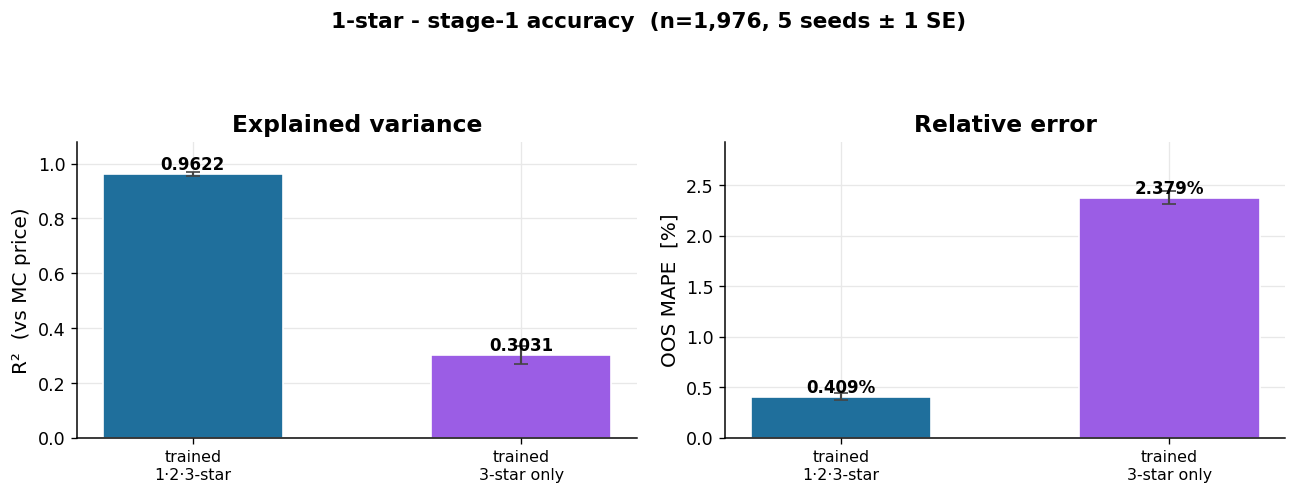

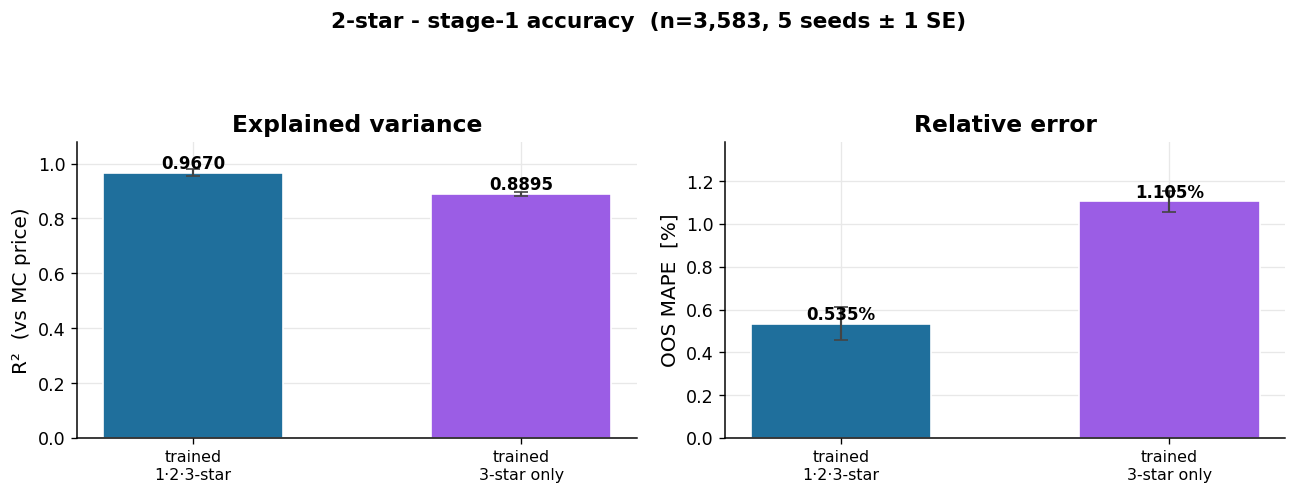

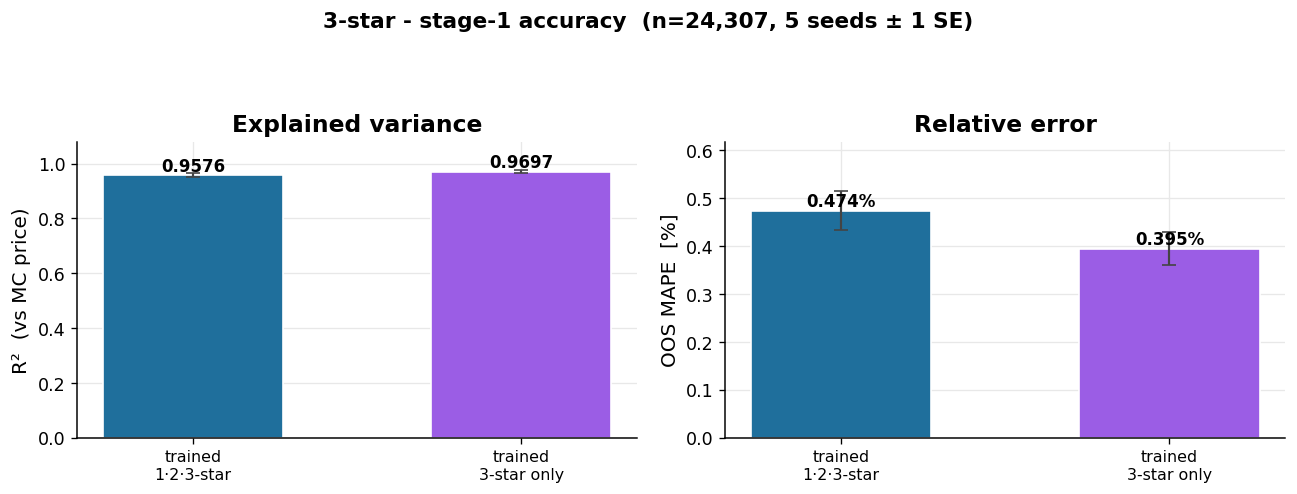

  star               model     n     R2  R2_se   MAPE  MAPE_se      MAE     RMSE        MSE      bias
1-star  trained 1·2·3-star  1976 0.9622 0.0063 0.4093   0.0315  39.0612  69.0835  4772.5278  -26.7611
1-star trained 3-star only  1976 0.3031 0.0333 2.3786   0.0649 227.2900 296.5809 87960.2191 -210.7301
2-star  trained 1·2·3-star  3583 0.9670 0.0118 0.5346   0.0751  50.0313  80.9515  6553.1406  -17.3648
2-star trained 3-star only  3583 0.8895 0.0072 1.1050   0.0492 103.1160 148.2558 21979.7821  -60.8891
3-star  trained 1·2·3-star 24307 0.9576 0.0079 0.4738   0.0412  45.4657  74.7323  5584.9169  -21.7162
3-star trained 3-star only 24307 0.9697 0.0052 0.3946   0.0342  37.8951  63.2041  3994.7589   -7.6278


In [2]:
# --- 1-A. 스타별 종합 R2 / MAPE ---
rows = []
for s, m in STARS:
    idx = oos[m[oos]]
    for lab, Pm in [("trained 1·2·3-star", P_all), ("trained 3-star only", P_3)]:
        p = np.nanmean(Pm, 0)
        r = mets(idx, p)
        r.update(star="{}-star".format(s), model=lab,
                 R2_se=seed_se(idx, Pm, "R2"), MAPE_se=seed_se(idx, Pm, "MAPE"))
        rows.append(r)
LV = pd.DataFrame(rows)
LV.to_csv(fm.stat("cat1_level"), index=False, encoding="utf-8-sig")

for s, _ in STARS:
    z = LV[LV.star == "{}-star".format(s)].set_index("model")
    fig, ax = plt.subplots(1, 2, figsize=(11.0, 4.2))
    for a, col, yl, ttl, fv in [(ax[0], "R2", "R²  (vs MC price)", "Explained variance", "{:.4f}"),
                                (ax[1], "MAPE", "OOS MAPE  [%]", "Relative error", "{:.3f}%")]:
        labs = ["trained 1·2·3-star", "trained 3-star only"]
        v = [z.loc[l, col] for l in labs]; e = [z.loc[l, col + "_se"] for l in labs]
        b = a.bar(range(2), v, .55, color=[C_NEW, C_OLD], edgecolor="white", lw=1,
                  yerr=e, capsize=4, error_kw=dict(lw=1.3, ecolor="#444"))
        for r_, val in zip(b, v):
            a.text(r_.get_x() + r_.get_width() / 2, val, fv.format(val), ha="center",
                   va="bottom", fontsize=10, fontweight="bold")
        a.set_xticks(range(2)); a.set_xticklabels([l.replace(" ", "\n", 1) for l in labs], fontsize=9.5)
        a.set_ylabel(yl); a.set_title(ttl, fontweight="bold"); a.margins(y=.20)
        if col == "R2":
            a.set_ylim(0, 1.08)
    fig.suptitle("{}-star - stage-1 accuracy  (n={:,}, 5 seeds ± 1 SE)".format(
        s, int(z.n.iloc[0])), fontsize=13, fontweight="bold")
    fig.tight_layout(rect=[0, 0, 1, .91])
    save(fig, "cat1_{}star_level".format(s))

print(LV[["star", "model", "n", "R2", "R2_se", "MAPE", "MAPE_se", "MAE", "RMSE", "MSE", "bias"]]
      .round(4).to_string(index=False))

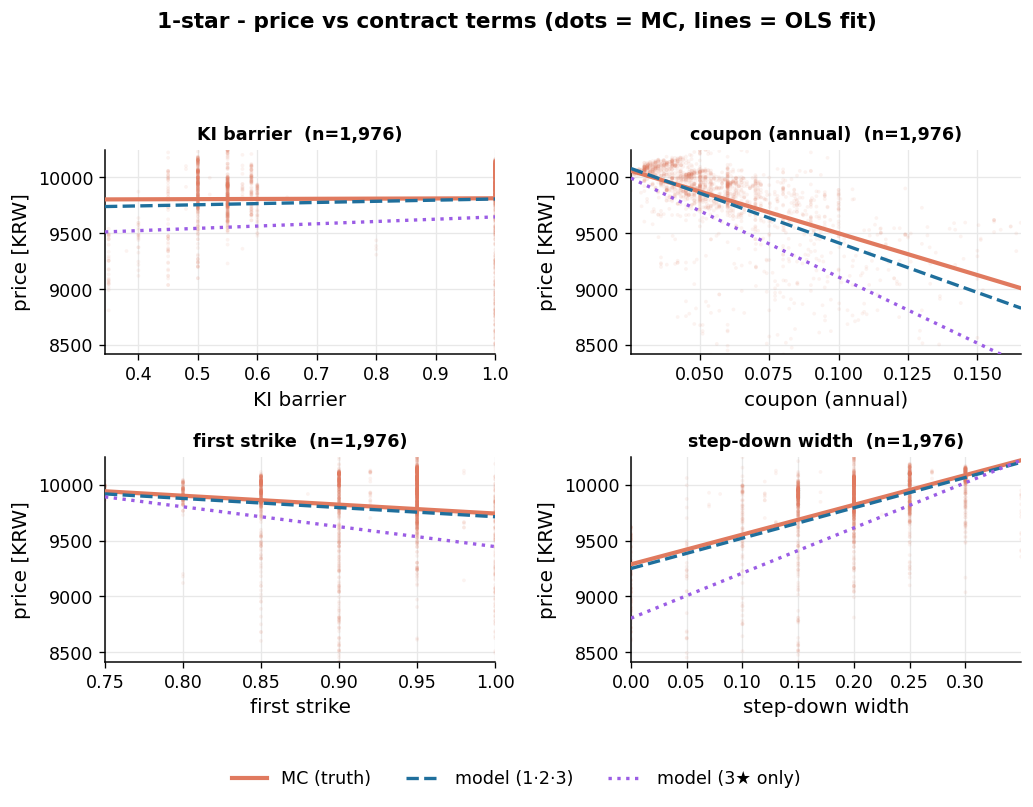

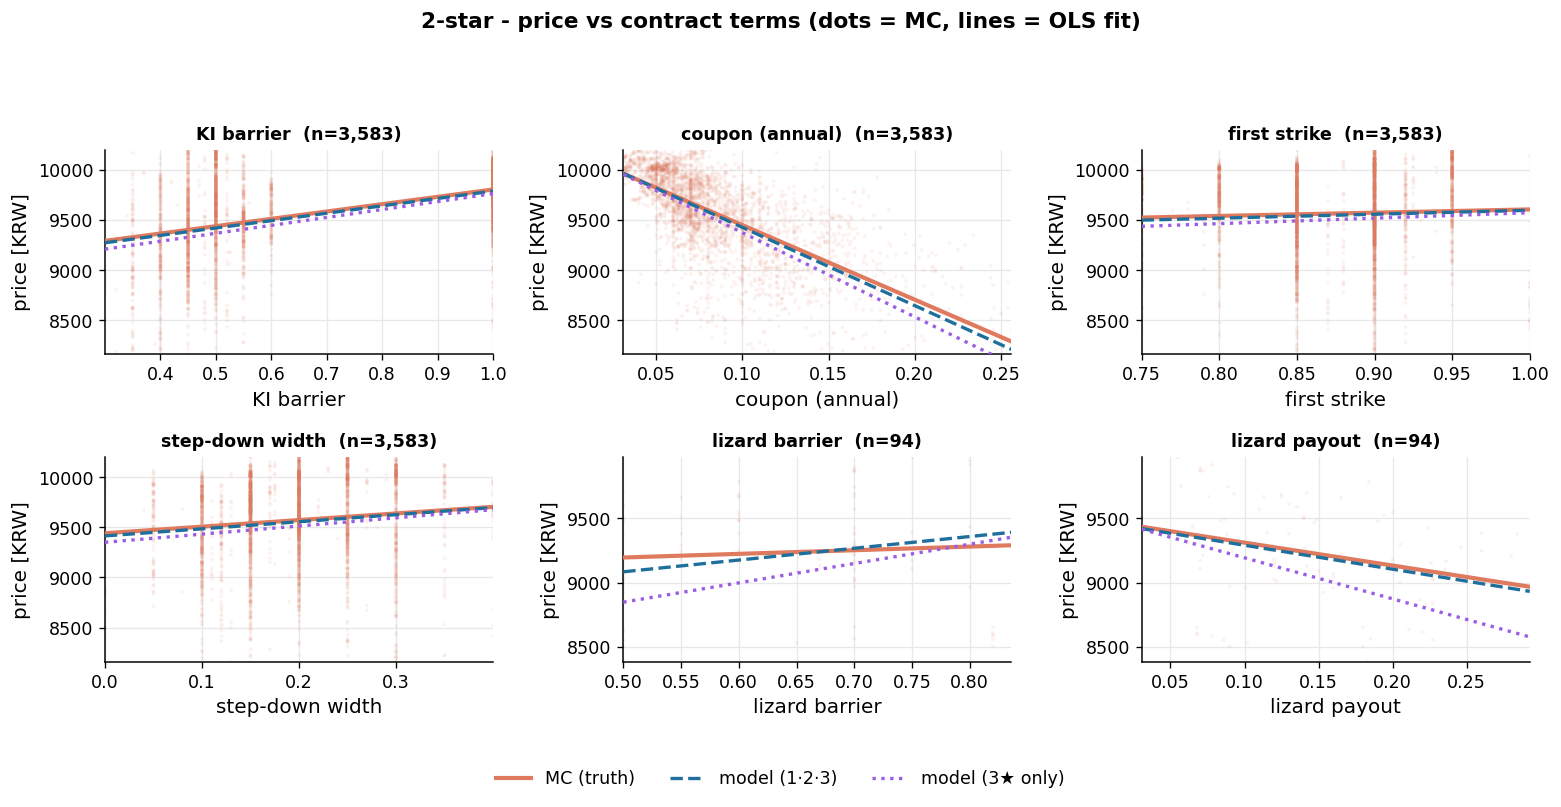

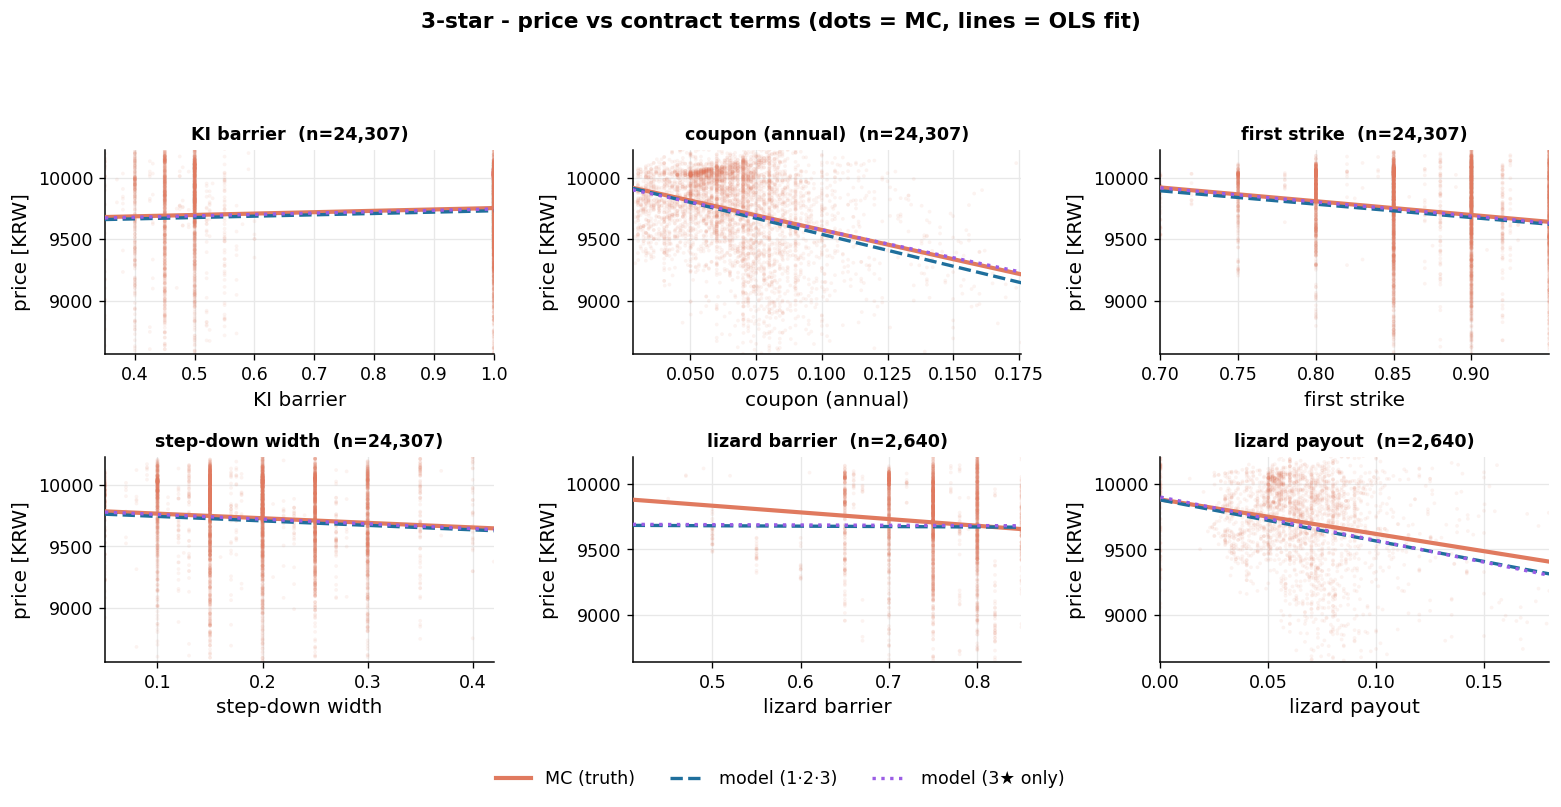

In [3]:
# --- 1-B. 계약조건 산점 + OLS (스타별) ---
for s, m in STARS:
    idx = oos[m[oos]]
    T = terms_for(idx)
    nc = 3 if len(T) > 4 else 2
    nr = int(np.ceil(len(T) / nc))
    fig, ax = plt.subplots(nr, nc, figsize=(4.4 * nc, 3.3 * nr))
    axes = np.atleast_1d(ax).ravel()
    for a, (lab, i) in zip(axes, T.items()):
        xv = TERMS[lab]
        pk = i if len(i) <= 5000 else rng.choice(i, 5000, replace=False)
        a.scatter(xv[pk], mc[pk], s=5, alpha=.09, color=C_MC, edgecolors="none", rasterized=True)
        lo_, hi_ = np.percentile(xv[i], [0.5, 99.5]); xx = np.linspace(lo_, hi_, 50)
        for nm, yv, c, ls in [("MC (truth)", mc, C_MC, "-"),
                              ("model (1·2·3)", pred, C_NEW, "--"),
                              ("model (3★ only)", pred3, C_OLD, ":")]:
            b1, se, b0 = ols_cluster(xv[i], yv[i], clu[i])
            a.plot(xx, b0 + b1 * xx, ls, color=c, lw=2.5 if ls == "-" else 2.0, label=nm, zorder=5)
        a.set_xlim(lo_, hi_); a.set_ylim(*np.percentile(mc[i], [1, 99]))
        a.set_xlabel(lab); a.set_ylabel("price [KRW]")
        a.set_title("{}  (n={:,})".format(lab, len(i)), fontweight="bold", fontsize=10.5)
    for a in axes[len(T):]:
        a.axis("off")
    h, l = axes[0].get_legend_handles_labels()
    fig.legend(h, l, loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(.5, -.02))
    fig.suptitle("{}-star - price vs contract terms (dots = MC, lines = OLS fit)".format(s),
                 fontsize=13, fontweight="bold")
    fig.tight_layout(rect=[0, .06, 1, .92])
    save(fig, "cat1_{}star_terms_ols".format(s))

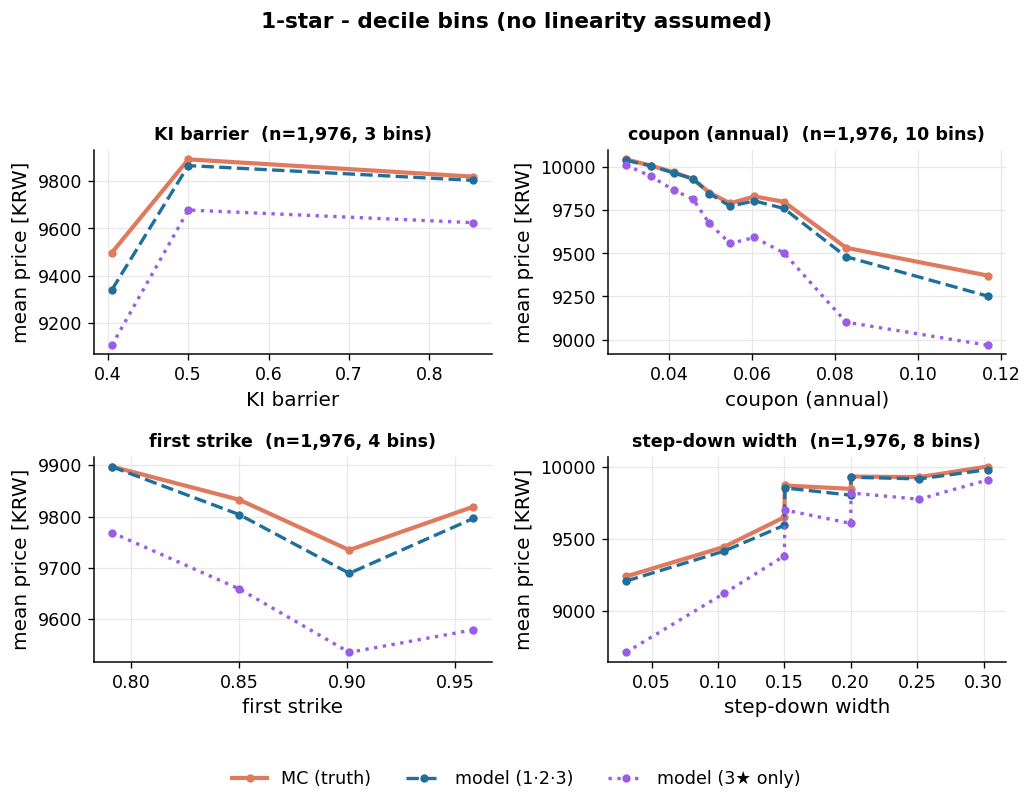

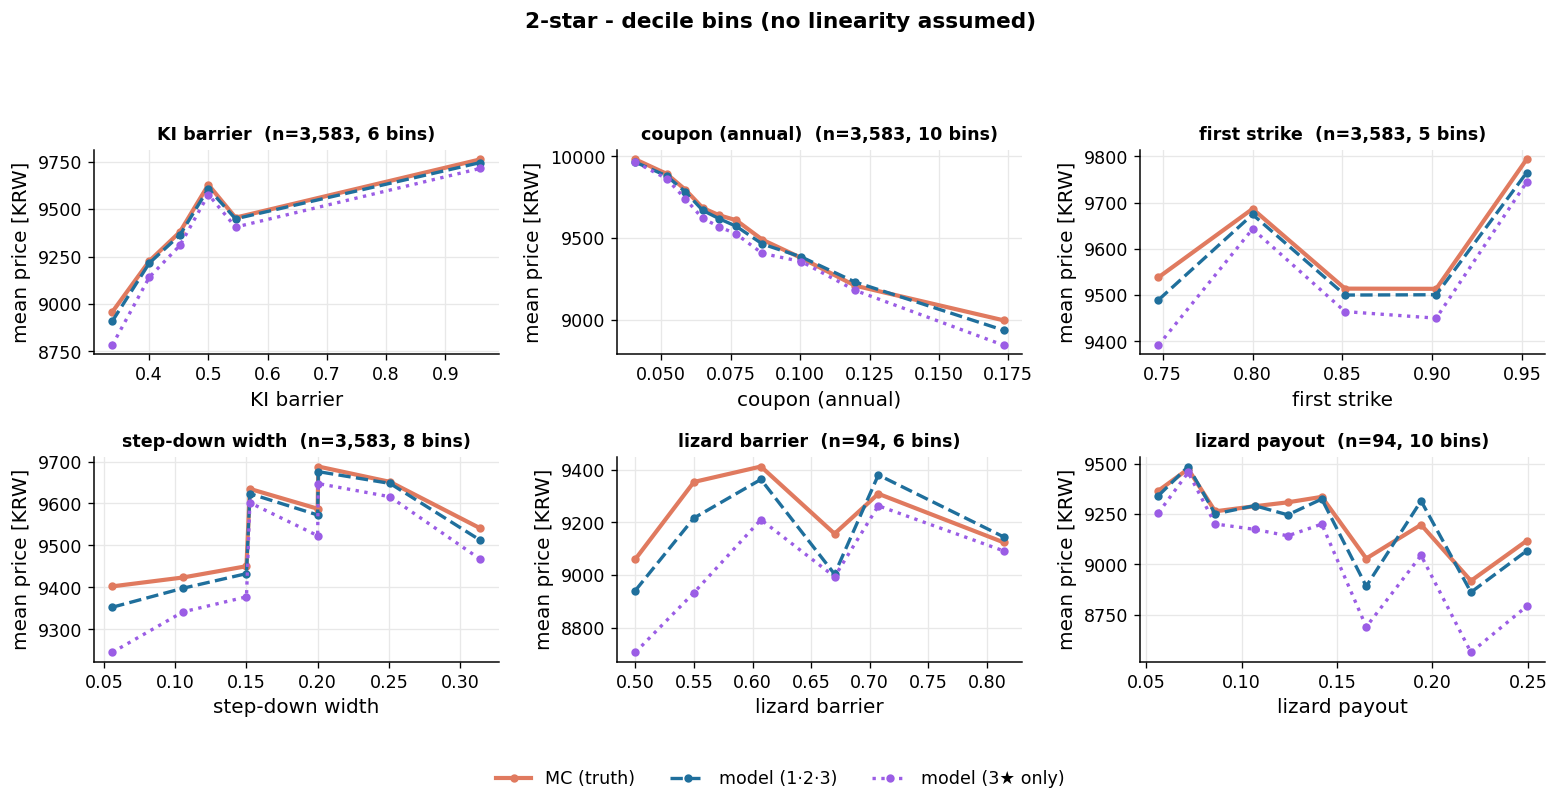

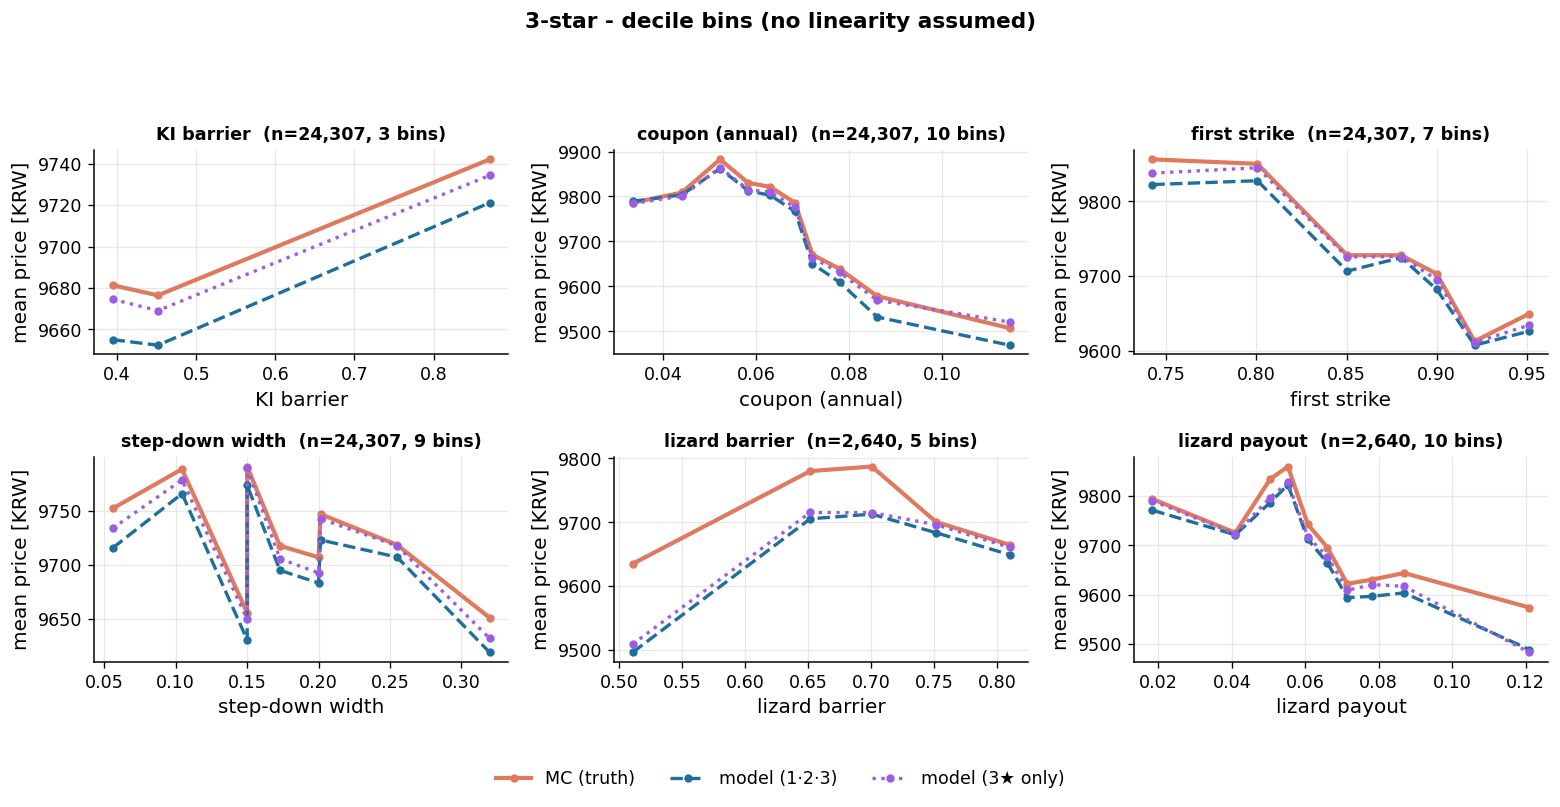

계약조건 기울기.  ratio = b(모델)/b(MC) 로 1.0 이 완벽, resid 는 0 이 완벽 (발행일 군집보정 SE)
  star          factor     n  MC_slope  model_slope  ratio     resid      se       t
1-star      KI barrier  1976    15.151      103.180  6.810    88.029  10.805   8.147
1-star coupon (annual)  1976 -7473.531    -8882.995  1.189 -1409.464  89.895 -15.679
1-star    first strike  1976  -796.908     -817.111  1.025   -20.203  33.742  -0.599
1-star step-down width  1976  2659.885     2713.388  1.020    53.502  29.403   1.820
2-star      KI barrier  3583   732.399      737.179  1.007     4.780   8.184   0.584
2-star coupon (annual)  3583 -7448.989    -7807.790  1.048  -358.801 148.684  -2.413
2-star    first strike  3583   324.906      393.238  1.210    68.333  36.293   1.883
2-star step-down width  3583   659.091      706.709  1.072    47.618  25.664   1.855
2-star  lizard barrier    94   284.752      917.936  3.224   633.183 131.029   4.832
2-star   lizard payout    94 -1788.944    -1870.462  1.046   -81.517 291.354  

In [4]:
# --- 1-C. 계약조건 구간평균 (선형 가정 없음, 스타별) ---
res_rows = []
for s, m in STARS:
    idx = oos[m[oos]]
    T = terms_for(idx)
    nc = 3 if len(T) > 4 else 2
    nr = int(np.ceil(len(T) / nc))
    fig, ax = plt.subplots(nr, nc, figsize=(4.4 * nc, 3.3 * nr))
    axes = np.atleast_1d(ax).ravel()
    for a, (lab, i) in zip(axes, T.items()):
        xv = TERMS[lab]; xs = xv[i]
        qq = np.unique(np.quantile(xs, np.linspace(0, 1, 11)))
        b = np.clip(np.digitize(xs, qq[1:-1]), 0, len(qq) - 2)
        cx = np.array([xs[b == j].mean() for j in range(len(qq) - 1)])
        for nm, yv, c, ls in [("MC (truth)", mc, C_MC, "-"),
                              ("model (1·2·3)", pred, C_NEW, "--"),
                              ("model (3★ only)", pred3, C_OLD, ":")]:
            cy = np.array([yv[i][b == j].mean() for j in range(len(qq) - 1)])
            a.plot(cx, cy, ls, marker="o", color=c, ms=4,
                   lw=2.5 if ls == "-" else 2.0, label=nm)
        a.set_xlabel(lab); a.set_ylabel("mean price [KRW]")
        a.set_title("{}  (n={:,}, {} bins)".format(lab, len(i), len(qq) - 1),
                    fontweight="bold", fontsize=10.5)
        # 잔차회귀도 같이 기록 (수치는 아래 표)
        smc, _, _ = ols_cluster(xv[i], mc[i], clu[i])
        for nm, yv in [("model (1·2·3)", pred), ("model (3★ only)", pred3)]:
            b1, se, _ = ols_cluster(xv[i], (yv - mc)[i], clu[i])
            res_rows.append(dict(star="{}-star".format(s), factor=lab, model=nm, n=len(i),
                                 MC_slope=smc, model_slope=smc + b1,
                                 ratio=(smc + b1) / smc if abs(smc) > 1e-9 else np.nan,
                                 resid=b1, se=se,
                                 rel_pct=b1 / smc * 100 if abs(smc) > 1e-9 else np.nan,
                                 t=b1 / se))
    for a in axes[len(T):]:
        a.axis("off")
    h, l = axes[0].get_legend_handles_labels()
    fig.legend(h, l, loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(.5, -.02))
    fig.suptitle("{}-star - decile bins (no linearity assumed)".format(s),
                 fontsize=13, fontweight="bold")
    fig.tight_layout(rect=[0, .06, 1, .92])
    save(fig, "cat1_{}star_terms_binned".format(s))

# 스타 구분 없는 전수(ALL)도 같은 정의로 기록한다 — 그림은 스타별로만 내고 수치는 표에 담는다
for lab, i in terms_for(oos).items():
    xv = TERMS[lab]
    smc, _, _ = ols_cluster(xv[i], mc[i], clu[i])
    for nm, yv in [("model (1·2·3)", pred), ("model (3★ only)", pred3)]:
        b1, se, _ = ols_cluster(xv[i], (yv - mc)[i], clu[i])
        res_rows.append(dict(star="ALL", factor=lab, model=nm, n=len(i),
                             MC_slope=smc, model_slope=smc + b1,
                             ratio=(smc + b1) / smc if abs(smc) > 1e-9 else np.nan,
                             resid=b1, se=se,
                             rel_pct=b1 / smc * 100 if abs(smc) > 1e-9 else np.nan,
                             t=b1 / se))

RS = pd.DataFrame(res_rows)
RS.to_csv(fm.stat("cat1_resid"), index=False, encoding="utf-8-sig")
print("계약조건 기울기.  ratio = b(모델)/b(MC) 로 1.0 이 완벽, resid 는 0 이 완벽 (발행일 군집보정 SE)")
print(RS[RS.model == "model (1·2·3)"][
    ["star", "factor", "n", "MC_slope", "model_slope", "ratio", "resid", "se", "t"]]
    .round(3).to_string(index=False))

---
# 범주 2. 스타별 기초자산별 · 상품구조별 성능

같은 모형을 **기초자산**(지수 vs 개별주식)과 **상품구조**(STEP/LIZARD × 낙인/노낙인)로 갈라서 봅니다.
1·2스타는 표본이 작으므로 건수(n)를 함께 읽어야 합니다.

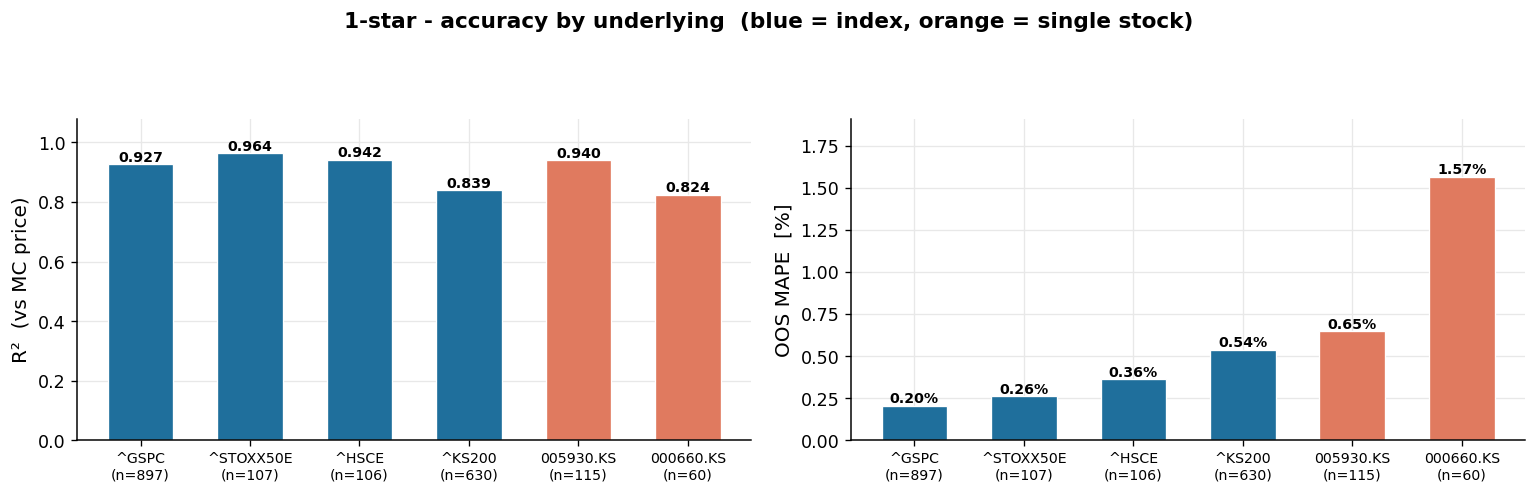

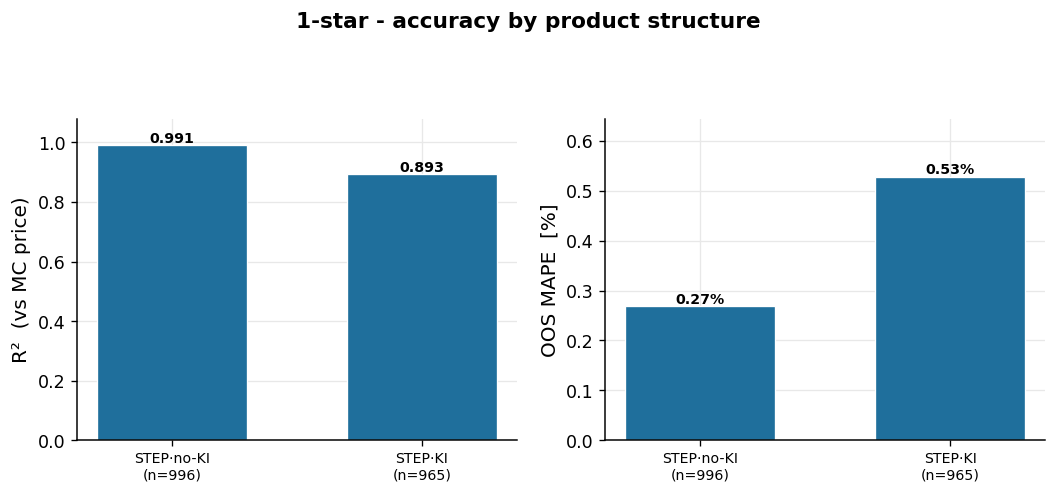

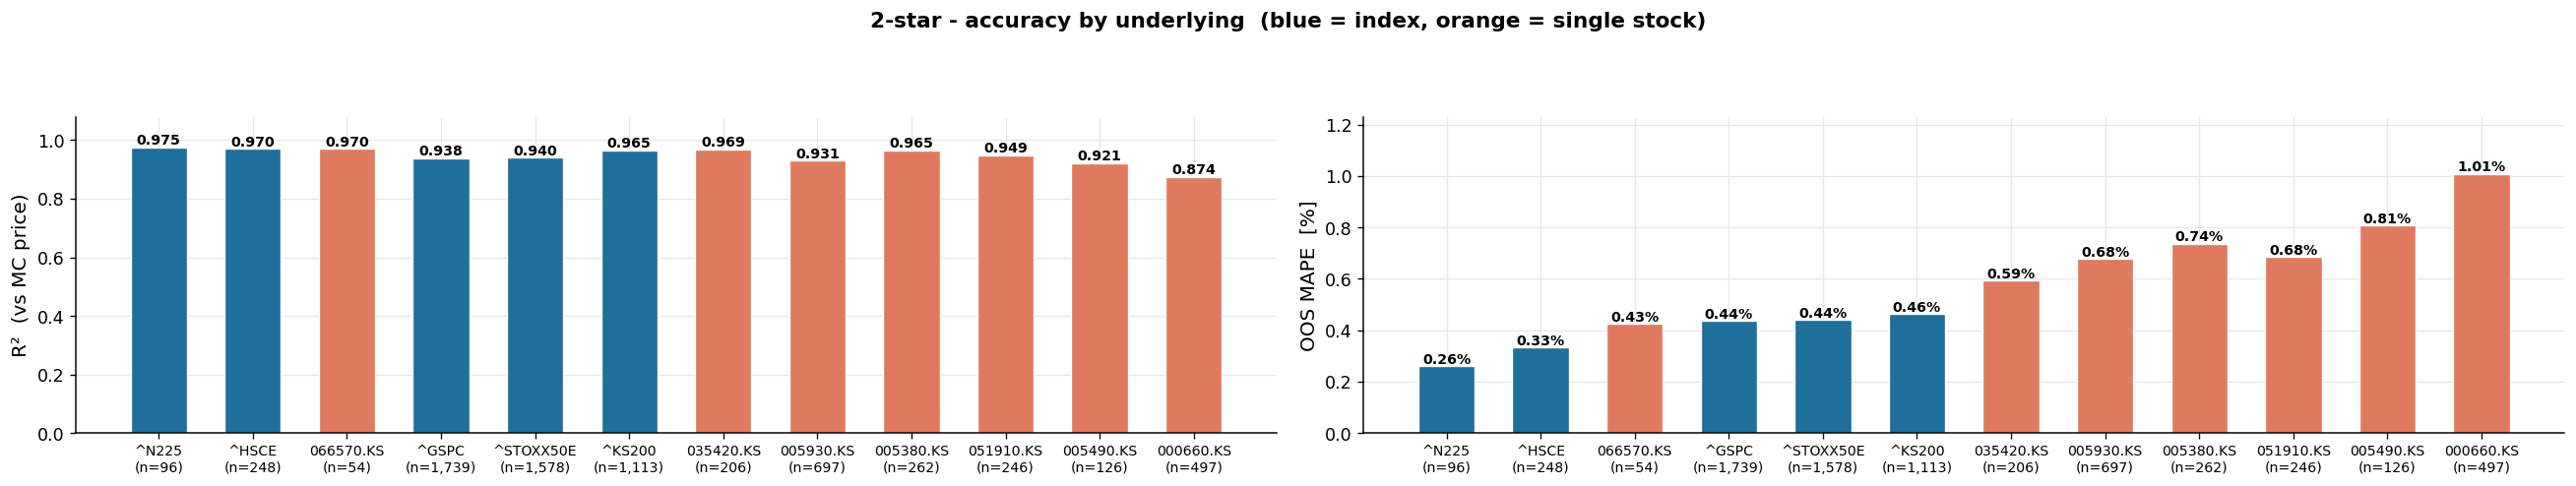

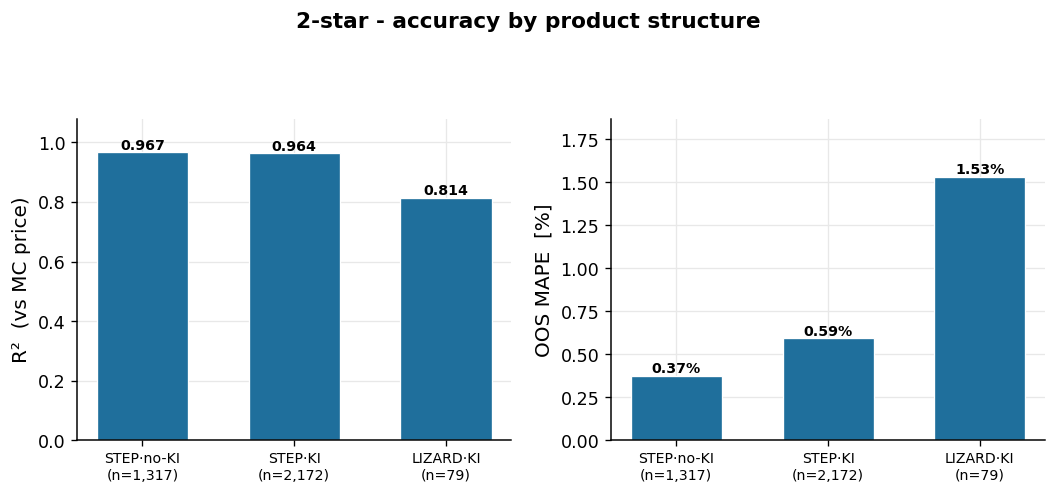

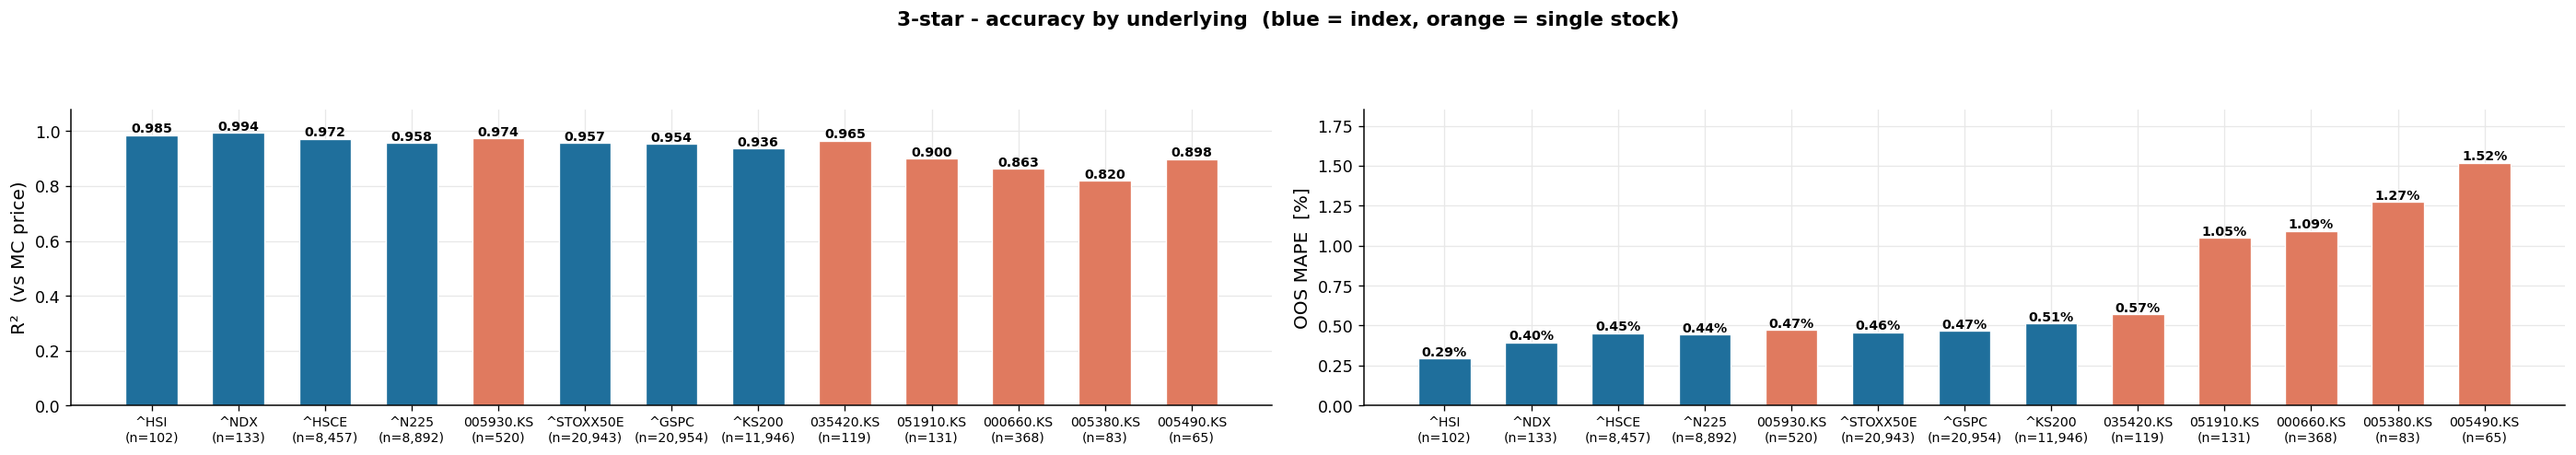

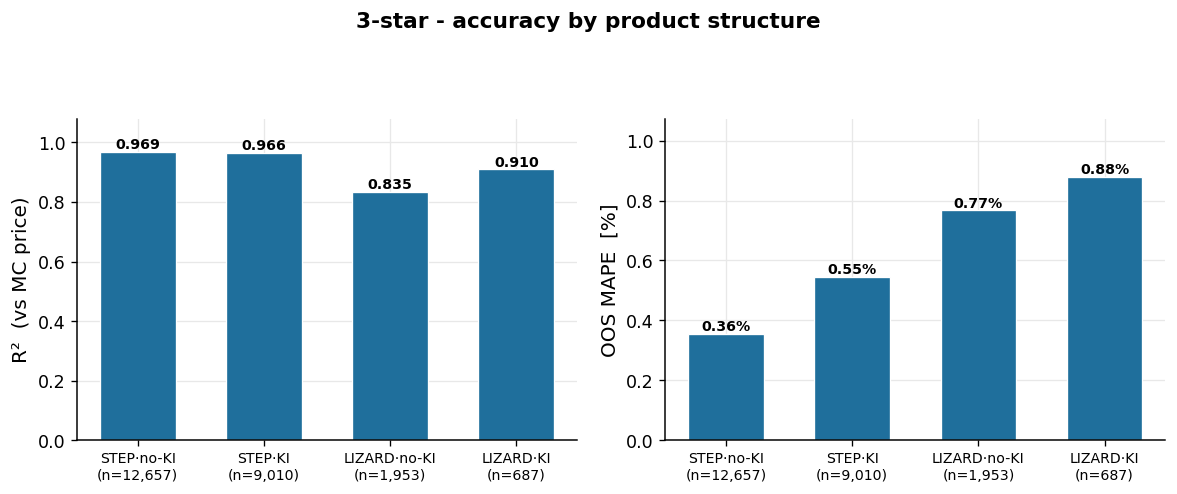

  star     label         kind     n     R2   MAPE      MAE     RMSE        MSE      bias
1-star     ^GSPC        index   897 0.9270 0.2037  20.3193  31.3199   980.9350   -5.9150
1-star ^STOXX50E        index   107 0.9637 0.2609  25.7584  37.0129  1369.9513  -21.1397
1-star     ^HSCE        index   106 0.9421 0.3621  34.9155  49.4414  2444.4499  -28.2470
1-star    ^KS200        index   630 0.8392 0.5358  51.4291  87.7187  7694.5771  -46.1519
1-star 005930.KS single stock   115 0.9403 0.6486  60.2016  77.3511  5983.1896  -45.4686
1-star 000660.KS single stock    60 0.8243 1.5663 141.9385 182.4831 33300.0944 -107.7169
2-star     ^N225        index    96 0.9752 0.2607  25.6726  43.2173  1867.7325   -1.8065
2-star     ^HSCE        index   248 0.9701 0.3315  31.7012  51.0370  2604.7748  -12.1245
2-star 066570.KS single stock    54 0.9696 0.4252  39.6742  63.7905  4069.2323  -23.4164
2-star     ^GSPC        index  1739 0.9382 0.4361  42.6620  61.4646  3777.9012  -23.2412
2-star ^STOXX50E     

In [5]:
d3 = pd.read_parquet(fm.DATA / "els3_dataset.parquet")[["item", "udl1", "udl2", "udl3"]]
d12 = pd.read_parquet(fm.DATA / "els12_dataset.parquet")[["item", "udl1", "udl2", "udl3"]]
UD = pd.concat([d3, d12], ignore_index=True).drop_duplicates("item").set_index("item")
tk_of = {it: sorted({t for t in UD.loc[it].tolist() if isinstance(t, str)})
         for it in D.ITEM if it in UD.index}
struct = (np.where(has_lz, "LIZARD", "STEP") + np.where(ki, "·KI", "·no-KI"))


def grouped_bar(G, title, fname, color_fn=None):
    """R² · MAPE 두 패널 막대. G 는 label/n/R2/MAPE 열을 가진 DataFrame."""
    fig, ax = plt.subplots(1, 2, figsize=(max(9.0, 1.5 * len(G) + 4), 4.2))
    cols = color_fn(G) if color_fn else [C_NEW] * len(G)
    for a, col, yl, fv in [(ax[0], "R2", "R²  (vs MC price)", "{:.3f}"),
                           (ax[1], "MAPE", "OOS MAPE  [%]", "{:.2f}%")]:
        b = a.bar(np.arange(len(G)), G[col], .6, color=cols, edgecolor="white", lw=.8)
        for r_, v in zip(b, G[col]):
            a.text(r_.get_x() + r_.get_width() / 2, v, fv.format(v), ha="center",
                   va="bottom", fontsize=8.5, fontweight="bold")
        a.set_xticks(np.arange(len(G)))
        a.set_xticklabels(["{}\n(n={:,})".format(l, n) for l, n in zip(G.label, G.n)],
                          fontsize=8.5, rotation=0)
        a.set_ylabel(yl); a.margins(y=.22)
        if col == "R2":
            a.set_ylim(0, 1.08)
    fig.suptitle(title, fontsize=13, fontweight="bold")
    fig.tight_layout(rect=[0, 0, 1, .90])
    save(fig, fname)


UDR, STR = [], []
for s, m in STARS:
    idx = oos[m[oos]]
    # 기초자산별
    bucket = {}
    for i in idx:
        for t in tk_of.get(D.ITEM[i], []):
            bucket.setdefault(t, []).append(i)
    rows = [dict(label=t, **mets(np.array(v))) for t, v in bucket.items()
            if len(v) >= max(MIN_N, 50)]
    if rows:
        G = pd.DataFrame(rows).sort_values("MAE")
        G["star"] = "{}-star".format(s)
        G["kind"] = np.where(G.label.str.startswith("^"), "index", "single stock")
        UDR.append(G)
        grouped_bar(G, "{}-star - accuracy by underlying  (blue = index, orange = single stock)".format(s),
                    "cat2_{}star_by_underlying".format(s),
                    color_fn=lambda g: [C_IDX if k == "index" else C_EQ for k in g.kind])
    # 상품구조별
    rows = [dict(label=g, **mets(idx[struct[idx] == g])) for g in np.unique(struct[idx])
            if (struct[idx] == g).sum() >= MIN_N]
    if rows:
        G = pd.DataFrame(rows).sort_values("MAE")
        G["star"] = "{}-star".format(s)
        STR.append(G)
        grouped_bar(G, "{}-star - accuracy by product structure".format(s),
                    "cat2_{}star_by_structure".format(s))

U = pd.concat(UDR, ignore_index=True); S2 = pd.concat(STR, ignore_index=True)
U.to_csv(fm.stat("cat2_by_underlying"), index=False, encoding="utf-8-sig")
S2.to_csv(fm.stat("cat2_by_structure"), index=False, encoding="utf-8-sig")
print(U[["star", "label", "kind", "n", "R2", "MAPE", "MAE", "RMSE", "MSE", "bias"]].round(4).to_string(index=False))
print()
print(S2[["star", "label", "n", "R2", "MAPE", "MAE", "RMSE", "MSE", "bias"]].round(4).to_string(index=False))

---
# 범주 3. 프라이서 — 공정가와 MC 의 분포 차이

MC 입력을 바꾸면 이론가가 시장 공정가에 얼마나 가까워지는가. **before vs after** 로 봅니다.

| | 정의 |
|---|---|
| **before** | NS 커브 · HV120 · q = 0 (변형 A) |
| **after** | 부트스트랩 커브 · EWMA120 (λ=0.99) · 연속 배당수익률 q (변형 B = **현행 방법론**) |

종전 노트북 14~17 이 쓰던 형식과 같되, **표본 200개가 아니라 3스타 전량**으로 그립니다
(`mc_A` 는 3스타에만 있습니다).

이론가는 무차익 값이므로 공정가와 일치할 이유가 없습니다. 여기서 보는 것은
**격차가 체계적으로 줄었는가** 하나뿐입니다.

In [6]:
V = pd.read_parquet(fm.CACHE / "mcvar" / "mc_variants.parquet").set_index("item")
S3 = pd.read_parquet(fm.DATA / "els3_dataset.parquet")[["item", "fair", "isu_ord", "tenor"]]
S3 = S3.join(V[["mc_A", "mc_B"]], on="item")
S3 = S3[np.isfinite(S3.mc_A) & np.isfinite(S3.mc_B)].reset_index(drop=True)
S3["e_bef"] = (S3.fair - S3.mc_A) * FACE
S3["e_aft"] = (S3.fair - S3.mc_B) * FACE
S3["year"] = pd.to_datetime([pd.Timestamp.fromordinal(int(o)) for o in S3.isu_ord]).year

LB = "before: NS · HV120 · q = 0"
LA = "after: bootstrap · EWMA120 (λ=0.99) · discrete div"
CB, CA = "#e07a5f", "#1f6f9c"
print("3스타 전량 {:,}건".format(len(S3)))
print("  before  편향 {:+.0f}원 | MAE {:.0f}원 | MAPE {:.2f}%".format(
    S3.e_bef.mean(), S3.e_bef.abs().mean(), (S3.e_bef.abs() / (S3.fair * FACE)).mean() * 100))
print("  after   편향 {:+.0f}원 | MAE {:.0f}원 | MAPE {:.2f}%".format(
    S3.e_aft.mean(), S3.e_aft.abs().mean(), (S3.e_aft.abs() / (S3.fair * FACE)).mean() * 100))

3스타 전량 58,913건
  before  편향 -564원 | MAE 637원 | MAPE 7.05%
  after   편향 -428원 | MAE 568원 | MAPE 6.27%


### 3-1. 격차 분포 — before vs after

변형 A(종전 입력: NS 커브 · 단순 역사적변동성 · 배당 0)와 변형 B(현행: 부트스트랩 커브 · EWMA · 연속 q)의
`공정가 − 이론가` 분포를 겹쳐 봅니다. 분포가 0 쪽으로 옮겨갔으면 입력 교체가 시장과의 격차를 줄인 것입니다.

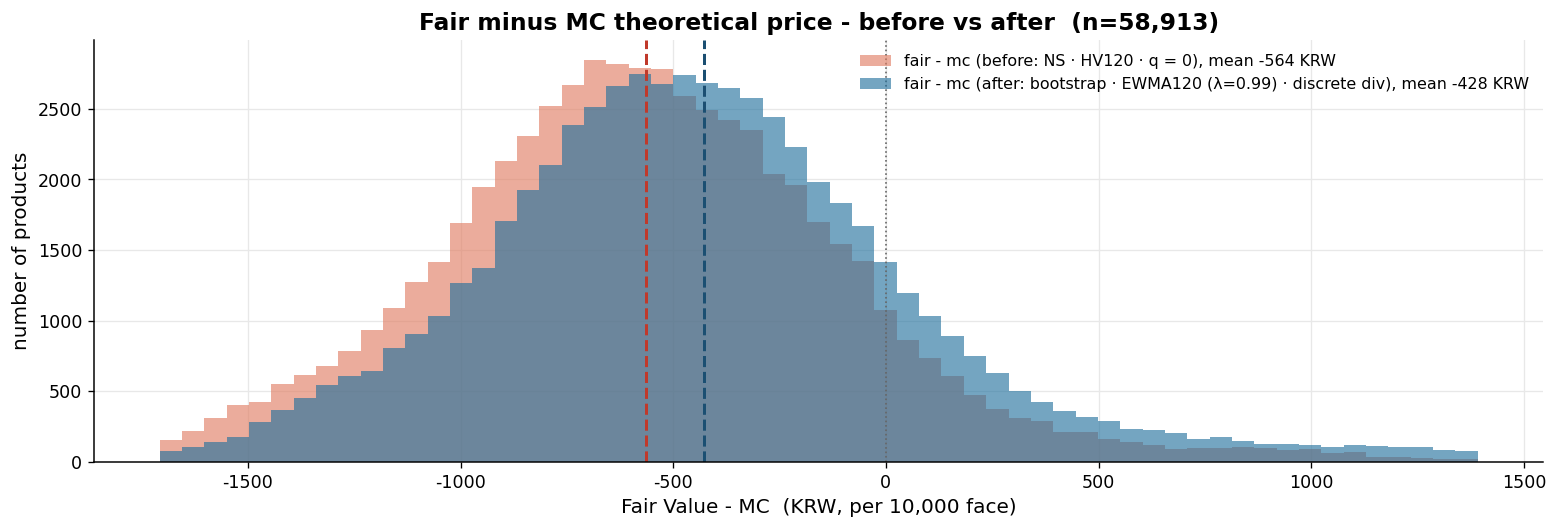

In [7]:
lo_, hi_ = np.percentile(np.r_[S3.e_bef, S3.e_aft], [0.5, 99.5])
bins = np.linspace(lo_, hi_, 60)
fig, a = plt.subplots(figsize=(13.2, 4.6))
a.hist(S3.e_bef, bins=bins, color=CB, alpha=.62,
       label="fair - mc ({}), mean {:+.0f} KRW".format(LB, S3.e_bef.mean()))
a.hist(S3.e_aft, bins=bins, color=CA, alpha=.62,
       label="fair - mc ({}), mean {:+.0f} KRW".format(LA, S3.e_aft.mean()))
a.axvline(S3.e_bef.mean(), color="#c0392b", lw=1.8, ls="--")
a.axvline(S3.e_aft.mean(), color="#1b4f72", lw=1.8, ls="--")
a.axvline(0, color="#666", lw=1.0, ls=":")
a.set_xlabel("Fair Value - MC  (KRW, per 10,000 face)")
a.set_ylabel("number of products")
a.set_title("Fair minus MC theoretical price - before vs after  (n={:,})".format(len(S3)),
            fontweight="bold")
a.legend(frameon=False, fontsize=9.5, loc="upper right")
fig.tight_layout()
save(fig, "cat3_fair_minus_mc_hist")

### 3-2. 공정가 구간별 오차

격차가 **가격대에 따라 체계적으로 달라지는지** 봅니다. 한쪽으로 기울어 있으면 특정 가격대에서
이론가가 꾸준히 비싸거나 싸다는 뜻이고, 그건 평균만 봐서는 안 보입니다.

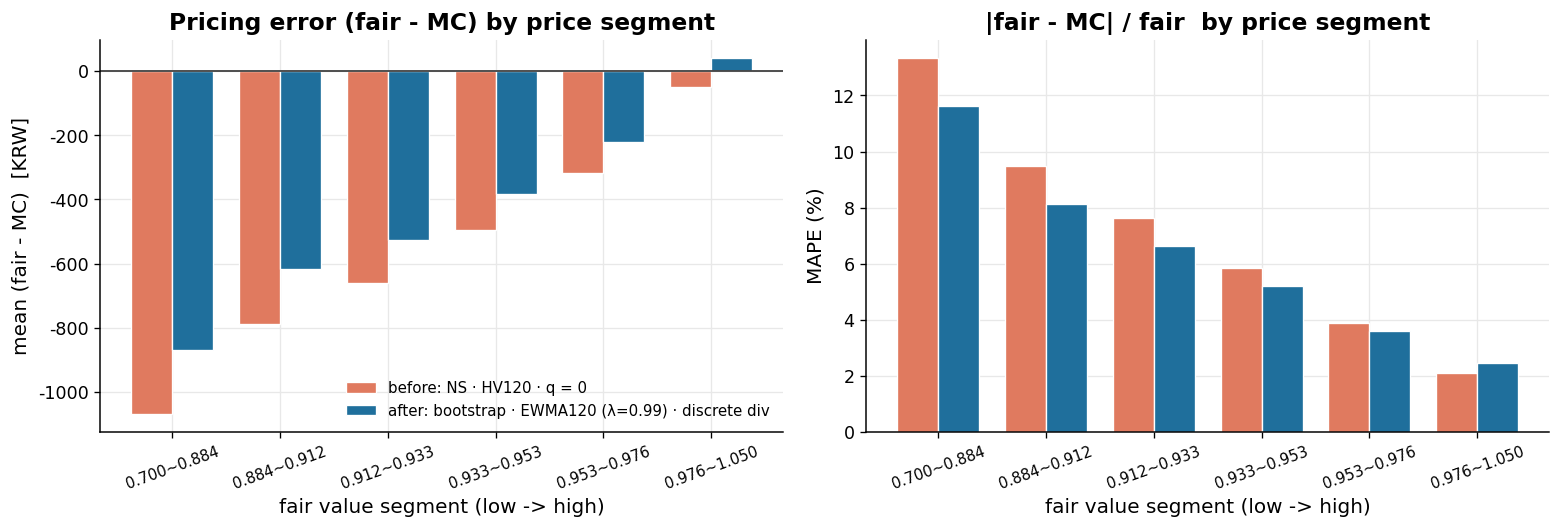

In [8]:
q = np.unique(np.quantile(S3.fair, np.linspace(0, 1, 7)))
b = np.clip(np.digitize(S3.fair, q[1:-1]), 0, len(q) - 2)
labs = ["{:.3f}~{:.3f}".format(q[j], q[j + 1]) for j in range(len(q) - 1)]
xp = np.arange(len(labs)); w = .38
fig, ax = plt.subplots(1, 2, figsize=(13.2, 4.6))
for j, (nm, col, c) in enumerate([(LB, "e_bef", CB), (LA, "e_aft", CA)]):
    ax[0].bar(xp + (j - .5) * w, [S3[col][b == k].mean() for k in range(len(labs))], w,
              color=c, edgecolor="white", lw=.8, label=nm)
    ax[1].bar(xp + (j - .5) * w,
              [(S3[col][b == k].abs() / (S3.fair[b == k] * FACE)).mean() * 100
               for k in range(len(labs))], w, color=c, edgecolor="white", lw=.8, label=nm)
ax[0].axhline(0, color="#444", lw=1.1)
ax[0].set_ylabel("mean (fair - MC)  [KRW]")
ax[0].set_title("Pricing error (fair - MC) by price segment", fontweight="bold")
ax[0].legend(frameon=False, fontsize=9, loc="lower right")
ax[1].set_ylabel("MAPE (%)")
ax[1].set_title("|fair - MC| / fair  by price segment", fontweight="bold")
for a in ax:
    a.set_xticks(xp); a.set_xticklabels(labs, rotation=20, fontsize=9)
    a.set_xlabel("fair value segment (low -> high)")
fig.tight_layout()
save(fig, "cat3_err_by_price_seg")

### 3-3. 발행연도별 오차

격차가 **시기에 따라** 달라지는지 봅니다. 특정 연도에 쏠려 있으면 그 시기의 시장환경이나
자료 품질을 따로 의심해야 합니다.

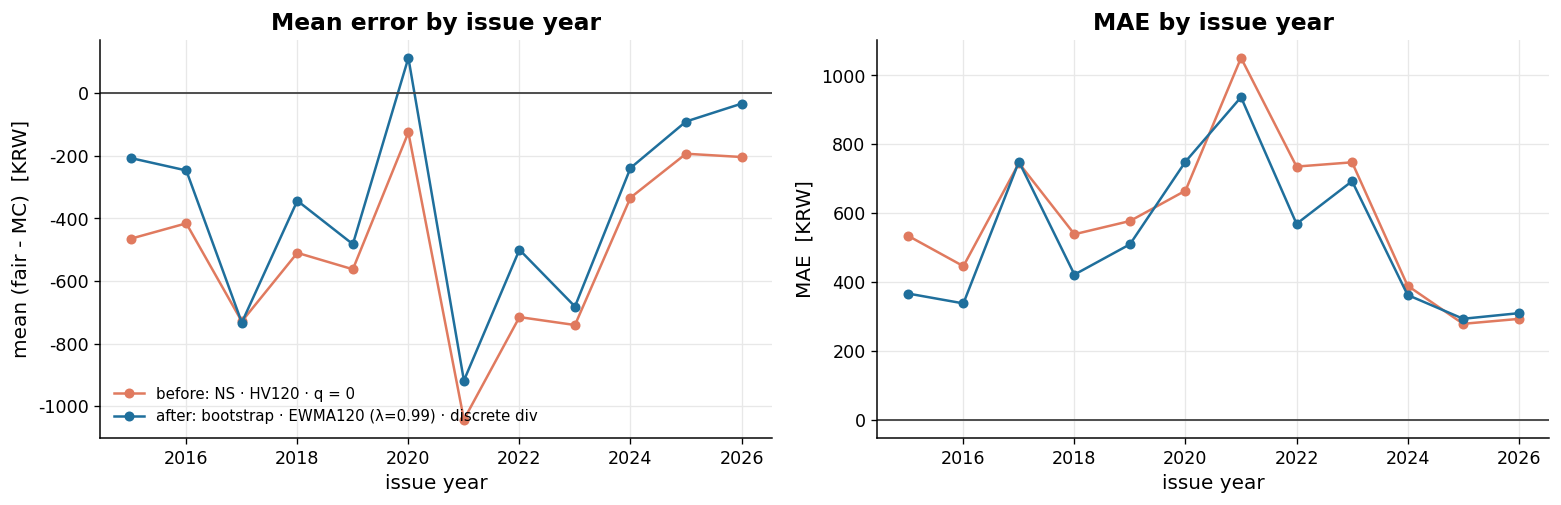

       e_bef        e_aft      
        mean count   mean count
year                           
2015  -465.0  4135 -207.0  4135
2016  -416.0  3846 -247.0  3846
2017  -729.0  5000 -733.0  5000
2018  -510.0  6657 -344.0  6657
2019  -563.0  8127 -483.0  8127
2020  -126.0  5161  113.0  5161
2021 -1043.0  7045 -918.0  7045
2022  -715.0  5705 -500.0  5705
2023  -741.0  5432 -682.0  5432
2024  -334.0  3101 -239.0  3101
2025  -194.0  3535  -91.0  3535
2026  -204.0  1169  -34.0  1169


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13.2, 4.4))
for nm, col, c in [(LB, "e_bef", CB), (LA, "e_aft", CA)]:
    g = S3.groupby("year")[col]
    ax[0].plot(g.mean().index, g.mean().values, "-o", color=c, ms=5, label=nm)
    ax[1].plot(g.mean().index, g.apply(lambda s: s.abs().mean()).values, "-o", color=c, ms=5,
               label=nm)
ax[0].axhline(0, color="#444", lw=1.1)
ax[0].set_ylabel("mean (fair - MC)  [KRW]")
ax[0].set_title("Mean error by issue year", fontweight="bold")
ax[0].legend(frameon=False, fontsize=9)
ax[1].axhline(0, color="#444", lw=1.1)
ax[1].set_ylabel("MAE  [KRW]")
ax[1].set_title("MAE by issue year", fontweight="bold")
for a in ax:
    a.set_xlabel("issue year")
fig.tight_layout()
save(fig, "cat3_by_year")

print(S3.groupby("year")[["e_bef", "e_aft"]].agg(["mean", "count"]).round(0).to_string())

### 3-4. 어느 입력이 격차를 줄였나 — ΔMC 분해

before → after 는 세 가지를 동시에 바꿉니다(커브 · 변동성 · 배당). 각각의 기여를 떼어서 봅니다.
중간 조합(할인만 부트스트랩, 드리프트까지 부트스트랩)이 필요해 **표본 200개**로만 가능합니다.
위 세 그림(전량 58,772건)과는 표본이 다릅니다.

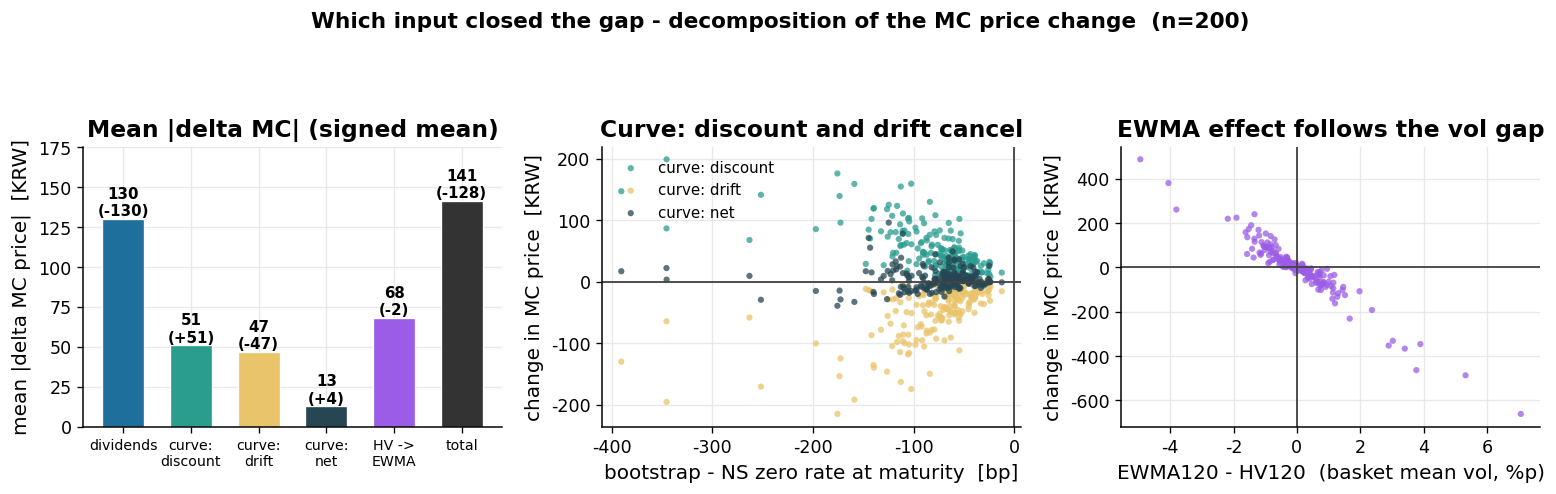

                  mean    std     min    max
dividends       -130.1   90.5  -492.0   11.5
curve: discount   51.1   36.5    -2.8  199.1
curve: drift     -46.8   41.9  -215.4   -0.6
curve: net         4.3   18.1   -39.3   96.1
HV -> EWMA        -1.8  118.8  -661.3  487.7
total           -127.7  160.1 -1031.2  263.4


In [10]:
BC = pd.read_csv(fm.stat("mc_boot_curve_200"), encoding="utf-8-sig")
comp = {"dividends": (BC.ns_h120 - BC.ns_h120_q0) * FACE,
        "curve: discount": (BC.bt_disc_h120 - BC.ns_h120) * FACE,
        "curve: drift": (BC.bt_h120 - BC.bt_disc_h120) * FACE,
        "curve: net": (BC.bt_h120 - BC.ns_h120) * FACE,
        "HV -> EWMA": (BC.bt_e120 - BC.bt_h120) * FACE,
        "total": (BC.bt_e120 - BC.ns_h120_q0) * FACE}
TICK = ["dividends", "curve:|discount", "curve:|drift", "curve:|net", "HV ->|EWMA", "total"]
COL = ["#1f6f9c", "#2a9d8f", "#e9c46a", "#264653", "#9b5de5", "#333333"]
labs = list(comp)

fig, ax = plt.subplots(1, 3, figsize=(13.2, 4.2))
b = ax[0].bar(np.arange(len(labs)), [comp[k].abs().mean() for k in labs], .62,
              color=COL, edgecolor="white", lw=.8)
for r_, k in zip(b, labs):
    ax[0].text(r_.get_x() + r_.get_width() / 2, r_.get_height(),
               "{:.0f}".format(comp[k].abs().mean()) + chr(10) + "({:+.0f})".format(comp[k].mean()),
               ha="center", va="bottom", fontsize=9, fontweight="bold")
ax[0].set_xticks(np.arange(len(labs)))
ax[0].set_xticklabels([t.replace("|", chr(10)) for t in TICK], fontsize=8.5)
ax[0].set_ylabel("mean |delta MC price|  [KRW]"); ax[0].margins(y=.24)
ax[0].set_title("Mean |delta MC| (signed mean)", fontweight="bold")

dz = (BC.bt_zT - BC.ns_zT) * 1e4
for nm, c in [("curve: discount", "#2a9d8f"), ("curve: drift", "#e9c46a"),
              ("curve: net", "#264653")]:
    ax[1].scatter(dz, comp[nm], s=14, alpha=.75, color=c, edgecolors="none", label=nm)
ax[1].axhline(0, color="#444", lw=1.1); ax[1].axvline(0, color="#444", lw=1.1)
ax[1].set_xlabel("bootstrap - NS zero rate at maturity  [bp]")
ax[1].set_ylabel("change in MC price  [KRW]")
ax[1].set_title("Curve: discount and drift cancel", fontweight="bold")
ax[1].legend(frameon=False, fontsize=9)

ax[2].scatter((BC.ew120 - BC.hv120) * 100, comp["HV -> EWMA"], s=14, alpha=.75,
              color="#9b5de5", edgecolors="none")
ax[2].axhline(0, color="#444", lw=1.1); ax[2].axvline(0, color="#444", lw=1.1)
ax[2].set_xlabel("EWMA120 - HV120  (basket mean vol, %p)")
ax[2].set_ylabel("change in MC price  [KRW]")
ax[2].set_title("EWMA effect follows the vol gap", fontweight="bold")
fig.suptitle("Which input closed the gap - decomposition of the MC price change  (n={:,})".format(len(BC)),
             fontsize=13, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, .90])
save(fig, "cat3_decomposition")

print(pd.DataFrame(comp).describe().T[["mean", "std", "min", "max"]].round(1).to_string())

### 3-5. 프라이서 속도 — MC vs 대리모형

같은 상품 200개를 두 경로로 가격합니다. **가격 산출만** 잽니다. 시장입력 조립(EWMA 변동성·영업일 상관·
커브 부트스트랩·배당)은 두 경로 모두 똑같이 필요하므로 측정에서 뺐습니다.

대리모형은 **Direct+단조손실 5시드 앙상블**로, 보고 성능과 같은 구성입니다.

배치가 커질수록 상품당 비용이 떨어지므로 '200개 요청' 과 '전량 일괄' 두 가지를 함께 냅니다.
하나만 내면 오해를 부릅니다.

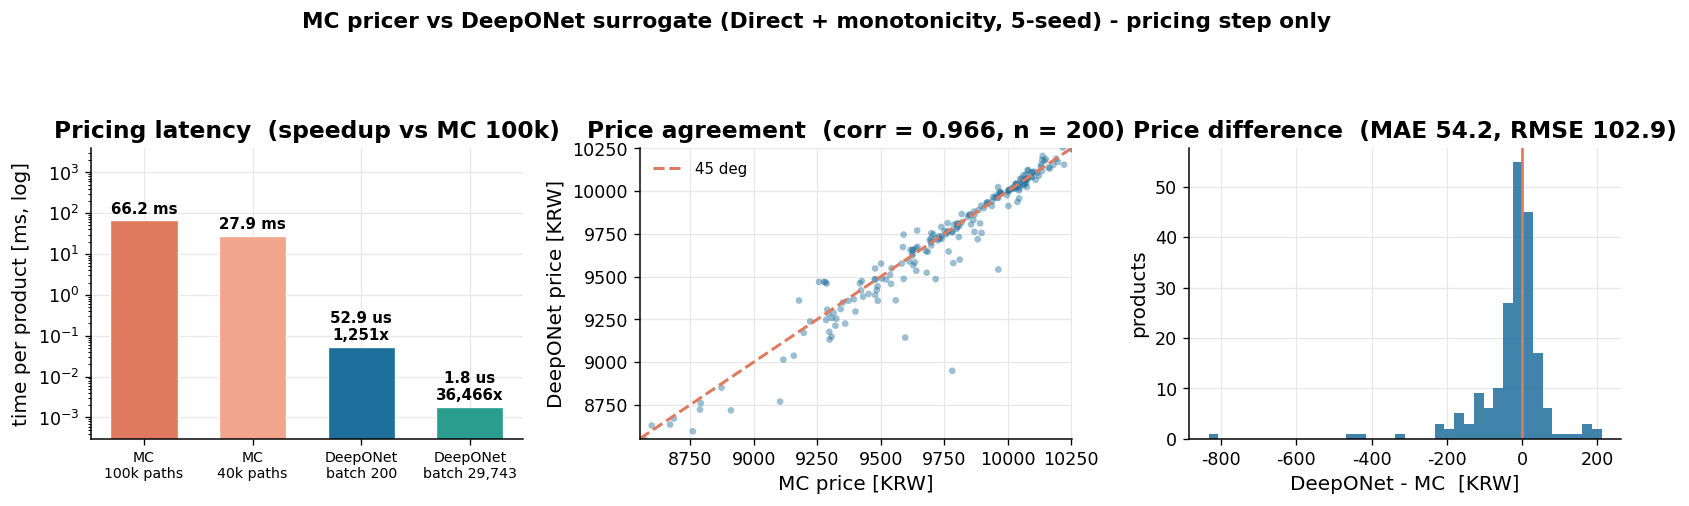

가격 산출만 측정 (시장입력 조립 제외) | 표본 200개 3스타 OOS
                        engine  ms_per_product     speedup
              MC 100,000 paths        66.21822         NaN
               MC 40,000 paths        27.86347         NaN
DeepONet (200-product request)         0.05292  1251.34818
  DeepONet (full book, 29,866)         0.00182 36466.36847

일치도  corr 0.9659 | R2 0.9204 | MAPE 0.566% | MAE 54.2원 | RMSE 102.9원 | 편향 -24.1원


In [11]:
import time
from module import anchors as AN, market as MK, mc_engine as ME

NSPD = 200
fold_s = np.full(D.n, -1, int)
for k_, (_, _, te_) in enumerate(D.WF):
    fold_s[te_] = k_
dfr = MK.dataset().set_index("item")
RET_s = MK.returns(); KBD_s = MK.calendar(RET_s)
rng_s = np.random.default_rng(0)

sel, st_args = [], []
for i_ in rng_s.permutation(oos[(D.nstar == 3)[oos]]):
    if len(sel) >= NSPD:
        break
    it_ = D.ITEM[i_]
    if it_ not in dfr.index:
        continue
    r_ = dfr.loc[it_]
    s_ = MK.state_for(r_, ret=RET_s, cal=KBD_s)
    if s_ is None:
        continue
    k_, p_, lb_, lp_ = MK.schedule(r_)
    st_args.append(((s_["sig"], s_["corr"], s_["dz"], float(r_["B"]), k_, float(r_["tenor"])),
                    dict(seed=int(r_["mc_seed"]), c=float(r_["coupon"]), pmts=p_,
                         lz_barr=lb_, lz_pmt=lp_, **s_["dkw"])))
    sel.append(int(i_))
sel = np.array(sel)

mc_t, mc_px = {}, {}
for npath in (40_000, 100_000):
    t0 = time.perf_counter()
    mc_px[npath] = np.array([float(ME.mc_daily_t(*a, n=npath, **kw)) for a, kw in st_args])
    mc_t[npath] = (time.perf_counter() - t0) / len(sel) * 1e3          # ms/상품

FN = {(s, k): AN.load_don(AN.path("ball_d", s, k))
      for s in range(5) for k in range(len(D.WF))}


def don_run(ix):
    """5시드 앙상블 전방계산. 폴드별 가중치로 그 폴드의 시험 상품만 예측한다."""
    Cx, Vx, Nx, fx = D.CURVE[ix], D.VC[ix], D.CON[ix].astype("float32"), fold_s[ix]
    acc = np.zeros(len(ix), "float64")
    for s in range(5):
        for k in range(len(D.WF)):
            m = fx == k
            if m.any():
                acc[m] += FN[(s, k)](Cx[m], Vx[m], Nx[m])
    return acc / 5


def don_time(ix, rep):
    for _ in range(3 if len(ix) < 5000 else 2):
        don_run(ix)
    ts = [0.0] * rep
    for j in range(rep):
        t0 = time.perf_counter(); don_run(ix); ts[j] = time.perf_counter() - t0
    return float(np.median(ts)) / len(ix) * 1e3                        # ms/상품


t_req = don_time(sel, 20)
t_book = don_time(oos, 5)
don_px = don_run(sel)

NREF = 100_000                      # 정본 라벨과 같은 경로 수 — 대리모델이 재현하려는 가격
mcp, dnp = mc_px[NREF] * FACE, don_px * FACE
ds = dnp - mcp
SPD = pd.DataFrame([
    dict(engine="MC 100,000 paths", ms_per_product=mc_t[100_000], speedup=np.nan),
    dict(engine="MC 40,000 paths", ms_per_product=mc_t[40_000], speedup=np.nan),
    dict(engine="DeepONet (200-product request)", ms_per_product=t_req,
         speedup=mc_t[NREF] / t_req),
    dict(engine="DeepONet (full book, {:,})".format(len(oos)), ms_per_product=t_book,
         speedup=mc_t[NREF] / t_book)])
SPD["agree_ref"] = "MC {:,} paths".format(NREF)     # 일치도를 어느 가격과 비교했는지 남긴다
SPD["agree_corr"] = float(np.corrcoef(mcp, dnp)[0, 1])
SPD["agree_MAE"] = np.abs(ds).mean()
SPD["agree_RMSE"] = float(np.sqrt((ds ** 2).mean()))
SPD["agree_MSE"] = float((ds ** 2).mean())
SPD["agree_MAPE"] = (np.abs(ds) / np.abs(mcp)).mean() * 100
SPD["agree_R2"] = 1 - (ds ** 2).sum() / ((mcp - mcp.mean()) ** 2).sum()
SPD["agree_bias"] = ds.mean()
SPD.to_csv(fm.stat("cat3_speed"), index=False, encoding="utf-8-sig")

LAB = ["MC|100k paths", "MC|40k paths", "DeepONet|batch 200", "DeepONet|batch 29,743"]
COLS = [C_MC, "#f0a58c", C_NEW, "#2a9d8f"]
fig, ax = plt.subplots(1, 3, figsize=(13.8, 4.3))

v = SPD.ms_per_product.values
b = ax[0].bar(np.arange(4), v, .62, color=COLS, edgecolor="white", lw=.8)
ax[0].set_yscale("log")
for j, (r_, sp) in enumerate(zip(b, SPD.speedup.values)):
    txt = "{:.3g} ms".format(v[j]) if v[j] >= 1 else "{:.1f} us".format(v[j] * 1e3)
    if np.isfinite(sp):
        txt += chr(10) + "{:,.0f}x".format(sp)
    ax[0].text(r_.get_x() + r_.get_width() / 2, r_.get_height() * 1.25, txt,
               ha="center", va="bottom", fontsize=9, fontweight="bold")
ax[0].set_xticks(np.arange(4))
ax[0].set_xticklabels([t.replace("|", chr(10)) for t in LAB], fontsize=8.5)
ax[0].set_ylabel("time per product [ms, log]")
ax[0].set_ylim(v.min() / 6, v.max() * 60)
ax[0].set_title("Pricing latency  (speedup vs MC 100k)", fontweight="bold")

ax[1].scatter(mcp, dnp, s=16, alpha=.45, color=C_NEW, edgecolors="none")
lo_, hi_ = np.percentile(np.r_[mcp, dnp], [0.5, 99.5])
ax[1].plot([lo_, hi_], [lo_, hi_], "--", color=C_MC, lw=1.8, label="45 deg")
ax[1].set_xlim(lo_, hi_); ax[1].set_ylim(lo_, hi_)
ax[1].set_xlabel("MC price [KRW]"); ax[1].set_ylabel("DeepONet price [KRW]")
ax[1].legend(frameon=False, fontsize=9)
ax[1].set_title("Price agreement  (corr = {:.3f}, n = {:,})".format(
    SPD.agree_corr.iloc[0], len(sel)), fontweight="bold")

ax[2].hist(ds, bins=40, color=C_NEW, alpha=.85)
ax[2].axvline(0, color=C_MC, lw=1.6)
ax[2].set_xlabel("DeepONet - MC  [KRW]"); ax[2].set_ylabel("products")
ax[2].set_title("Price difference  (MAE {:.1f}, RMSE {:.1f})".format(
    SPD.agree_MAE.iloc[0], SPD.agree_RMSE.iloc[0]), fontweight="bold")

fig.suptitle("MC pricer vs DeepONet surrogate (Direct + monotonicity, 5-seed) "
             "- pricing step only", fontsize=13, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, .90])
save(fig, "cat3_speed")

print("가격 산출만 측정 (시장입력 조립 제외) | 표본 {:,}개 3스타 OOS".format(len(sel)))
print(SPD[["engine", "ms_per_product", "speedup"]].round(5).to_string(index=False))
print()
print("일치도  corr {:.4f} | R2 {:.4f} | MAPE {:.3f}% | MAE {:.1f}원 | RMSE {:.1f}원 | 편향 {:+.1f}원".format(
    SPD.agree_corr.iloc[0], SPD.agree_R2.iloc[0], SPD.agree_MAPE.iloc[0],
    SPD.agree_MAE.iloc[0], SPD.agree_RMSE.iloc[0], SPD.agree_bias.iloc[0]))

---
# 범주 4. 공정가 관점에서 본 ELS 상품

모형이 아니라 **상품 자체**를 봅니다. 공정가비율이 계약조건·구조·시점에 따라 어떻게 분포하는가.

여기에는 모형도 MC 도 등장하지 않습니다. 유니버스가 어떤 상품들로 이루어져 있는지를 보는 절이라,
**앞 범주의 성능 수치를 해석할 때 배경으로** 쓰입니다. 예를 들어 어떤 구조의 표본이 얇은지 가늠할 수 있습니다.

C:\Users\Juhwankim\AppData\Local\Temp\ipykernel_15888\3103205544.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax[0, 1].boxplot([fr[st_o == l] for l in lab], labels=[l.replace("·", "\n") for l in lab],
C:\Users\Juhwankim\AppData\Local\Temp\ipykernel_15888\3103205544.py:19: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax[0, 2].boxplot([fr[ns_o == s] for s, _ in STARS],


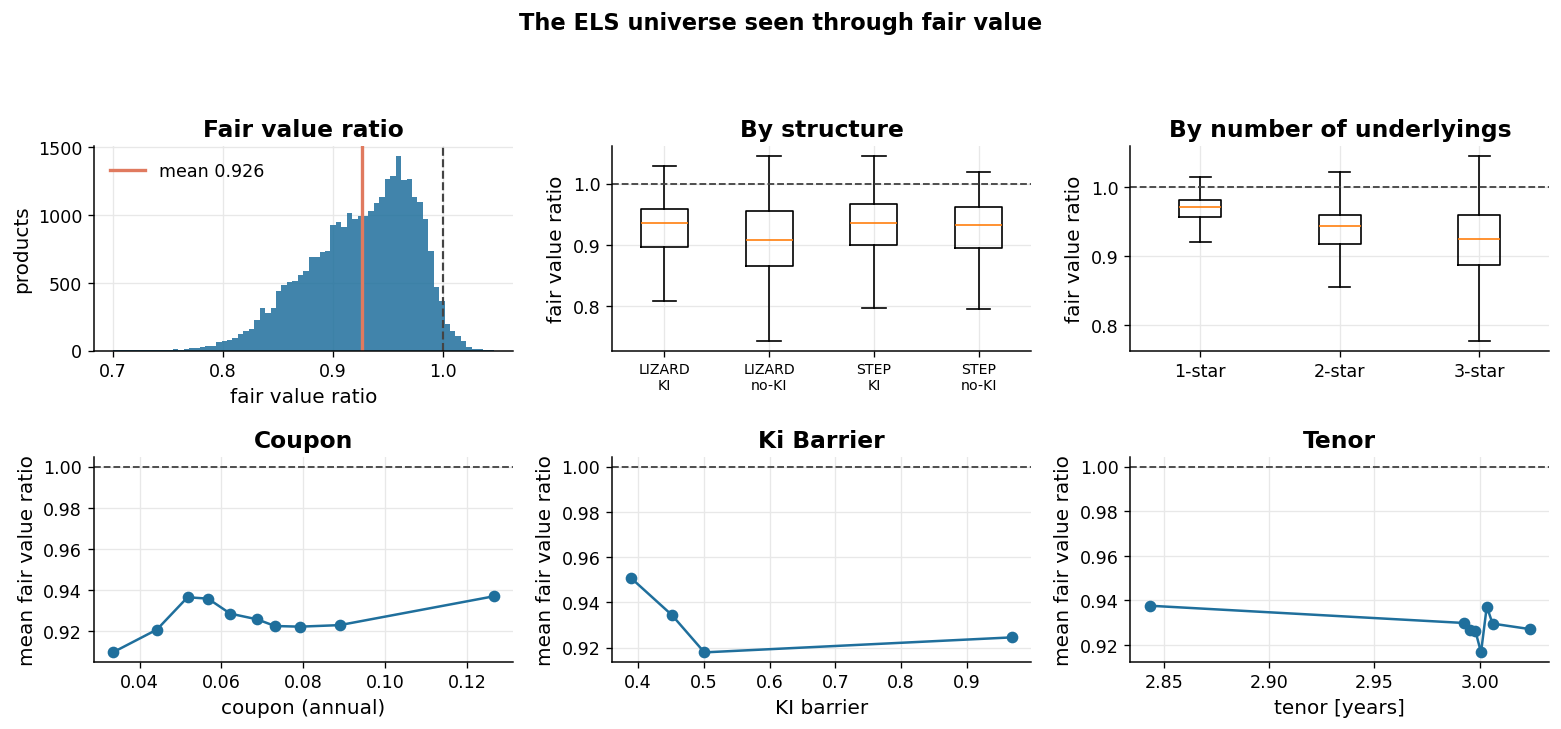

In [12]:
fr = D.FAIR[oos]
fig, ax = plt.subplots(2, 3, figsize=(13.2, 6.2))
ax[0, 0].hist(fr, bins=70, color=C_NEW, alpha=.85)
ax[0, 0].axvline(1.0, color="#444", lw=1.3, ls="--")
ax[0, 0].axvline(fr.mean(), color=C_MC, lw=2, label="mean {:.3f}".format(fr.mean()))
ax[0, 0].set_xlabel("fair value ratio"); ax[0, 0].set_ylabel("products")
ax[0, 0].set_title("Fair value ratio", fontweight="bold"); ax[0, 0].legend(frameon=False)

st_o = struct[oos]
lab = sorted(np.unique(st_o))
ax[0, 1].boxplot([fr[st_o == l] for l in lab], labels=[l.replace("·", "\n") for l in lab],
                 showfliers=False)
ax[0, 1].axhline(1.0, color="#444", lw=1.1, ls="--")
ax[0, 1].set_ylabel("fair value ratio")
ax[0, 1].set_title("By structure", fontweight="bold")
ax[0, 1].tick_params(axis="x", labelsize=8.5)

ns_o = D.nstar[oos]
ax[0, 2].boxplot([fr[ns_o == s] for s, _ in STARS],
                 labels=["{}-star".format(s) for s, _ in STARS], showfliers=False)
ax[0, 2].axhline(1.0, color="#444", lw=1.1, ls="--")
ax[0, 2].set_ylabel("fair value ratio")
ax[0, 2].set_title("By number of underlyings", fontweight="bold")

for a, (xv, xl) in zip(ax[1], [(D.CON[oos, CT.iC], "coupon (annual)"),
                               (D.CON[oos, CT.iB], "KI barrier"),
                               (D.CON[oos, CT.iT], "tenor [years]")]):
    qq = np.unique(np.quantile(xv, np.linspace(0, 1, 11)))
    b = np.clip(np.digitize(xv, qq[1:-1]), 0, len(qq) - 2)
    a.plot([xv[b == j].mean() for j in range(len(qq) - 1)],
           [fr[b == j].mean() for j in range(len(qq) - 1)], "-o", color=C_NEW)
    a.axhline(1.0, color="#444", lw=1.1, ls="--")
    a.set_xlabel(xl); a.set_ylabel("mean fair value ratio")
    a.set_title(xl.split(" [")[0].split(" (")[0].title(), fontweight="bold")
fig.suptitle("The ELS universe seen through fair value", fontsize=13.5, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, .93])
save(fig, "cat4_universe_fair")

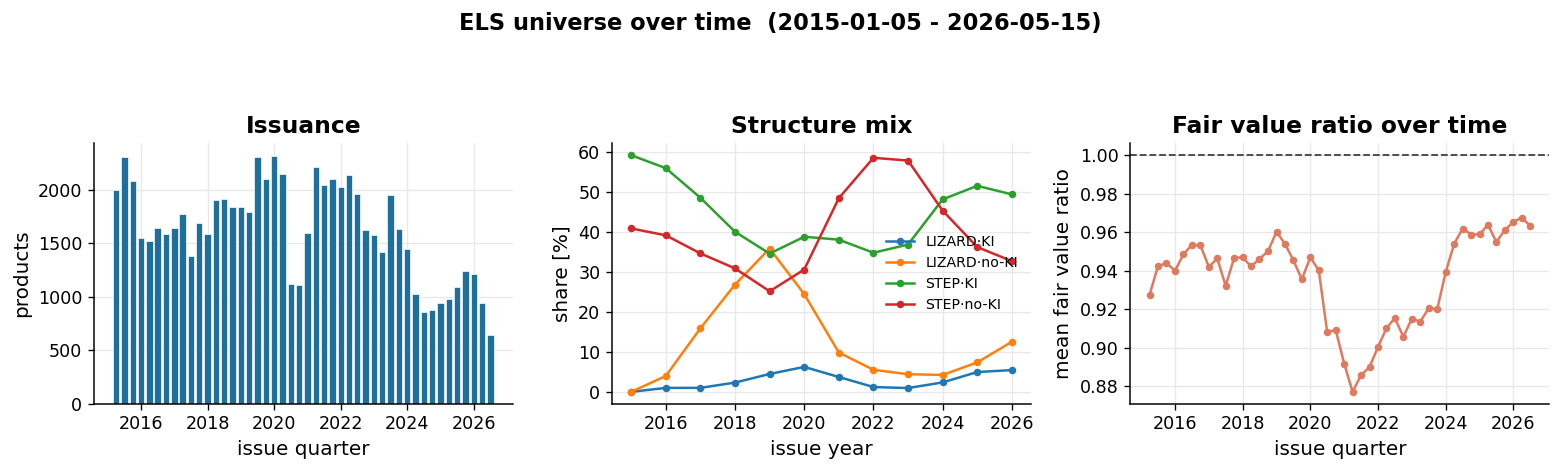

In [13]:
# 발행 추이와 구성 변화
dt = pd.to_datetime([pd.Timestamp.fromordinal(int(o)) for o in D.ORD])
fig, ax = plt.subplots(1, 3, figsize=(13.2, 4.0))
cnt = pd.Series(1, index=dt).resample("QE").sum()
ax[0].bar(cnt.index, cnt.values, width=70, color=C_NEW, edgecolor="white", lw=.4)
ax[0].set_xlabel("issue quarter"); ax[0].set_ylabel("products")
ax[0].set_title("Issuance", fontweight="bold")

mix = pd.crosstab(dt.to_period("Y"), struct, normalize="index") * 100
for c in mix.columns:
    ax[1].plot(mix.index.year, mix[c], "-o", ms=3.5, label=c)
ax[1].set_xlabel("issue year"); ax[1].set_ylabel("share [%]")
ax[1].set_title("Structure mix", fontweight="bold"); ax[1].legend(frameon=False, fontsize=8.5)

sf = pd.Series(D.FAIR, index=dt).resample("QE").mean()
ax[2].plot(sf.index, sf.values, "-o", color=C_MC, ms=3.5)
ax[2].axhline(1.0, color="#444", lw=1.1, ls="--")
ax[2].set_xlabel("issue quarter"); ax[2].set_ylabel("mean fair value ratio")
ax[2].set_title("Fair value ratio over time", fontweight="bold")
fig.suptitle("ELS universe over time  ({} - {})".format(dt.min().date(), dt.max().date()),
             fontsize=13.5, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, .91])
save(fig, "cat4_universe_time")

---
# 부록. 7종 모형 비교 · 전수 횡단면 기울기

앞의 네 범주는 기준 모형(Direct+단조) 두 벌만 씁니다. 여기서는 저장된 **7종 전부**를 같은 폴드·같은
시험집합에서 비교하고, 계약조건 기울기를 OOS 전수 횡단면으로 다시 잽니다.

**7종이란.** 세 축의 조합입니다. 구조(DeepONet / XGBoost) × 학습 풀(통합 / 3스타만) ×
타깃·입력(Direct / Residual, V_base 피처 추가 여부). XGBoost 는 계약조건을 **표 형태**로 받는
일반적인 부스팅 모형으로, 연산자망이 정말 필요한지를 가늠하는 벤치마크입니다.

**기울기를 두 방식으로 재는 이유.** 각각 장단점이 반대입니다.

| 방식 | 어떻게 | 장점 | 한계 |
|---|---|---|---|
| `allstar_slope` | 기준상품의 계약조건을 인위적으로 흔들어 MC 를 다시 계산 | 참값과 직접 비교 | 상품 수가 적음 |
| `xsec_slope` | OOS 전수 상품을 그대로 쓰는 횡단면 회귀 | 표본이 큼 | 교란이 섞임 |

둘이 같은 방향을 가리키면 신뢰할 만합니다.

| 산출물 | 내용 |
|---|---|
| `result/image/allstar.png` | 7종 × 스타별 R²·MAPE + 요인별 기울기 배수 |
| `allstar_level.csv` · `allstar_slope.csv` · `allstar_slope_raw.csv` | 위 수치 |
| `xsec_slope.csv` · `xsec_resid.csv` | 전수 횡단면 기울기와 잔차회귀 |

`eval_all_stars` 는 노트북 1의 1-0 이 만든 `mc_check_allstar.csv` 를 읽습니다. 없으면 건너뜁니다.


=== ALL (n=29,866, MC sd 378원) ===
  Direct+m (1·2·3)           R2 0.9484+-0.0078 | MAPE 0.547 | MAE  52.3원 | 편향  -21.5원
  Direct+m (3star only)      R2 0.9015+-0.0036 | MAPE 0.700 | MAE  66.8원 | 편향  -27.5원
  XGBoost (1·2·3)            R2 0.9025+-0.0007 | MAPE 0.764 | MAE  72.8원 | 편향  -15.2원
  XGBoost (3star only)       R2 0.8344+-0.0027 | MAPE 0.957 | MAE  91.5원 | 편향  -46.1원
  Resid+f+m (1·2·3)          R2 0.9801+-0.0002 | MAPE 0.335 | MAE  32.2원 | 편향   -2.9원
  Resid+f+m (3star only)     R2 0.9662+-0.0011 | MAPE 0.426 | MAE  40.7원 | 편향   -7.8원
  Direct+f+m (1·2·3)         R2 0.9719+-0.0012 | MAPE 0.403 | MAE  38.7원 | 편향   -0.3원

=== 1star (n=1,976, MC sd 355원) ===
  Direct+m (1·2·3)           R2 0.9516+-0.0063 | MAPE 0.478 | MAE  45.8원 | 편향  -26.8원
  Direct+m (3star only)      R2 0.2692+-0.0333 | MAPE 2.411 | MAE 230.6원 | 편향 -210.7원
  XGBoost (1·2·3)            R2 0.8472+-0.0031 | MAPE 0.899 | MAE  85.6원 | 편향  -46.6원
  XGBoost (3star only)       R2 0.1656+-0.0258 | MAPE 2.402 | MAE 2


=== 스타별 기울기 / MC 배수 (1.00 = 정답) ===
                                  MC  Direct+m (1·2·3)  Direct+m (3star only)  XGBoost (1·2·3)  XGBoost (3star only)  Resid+f+m (1·2·3)  Resid+f+m (3star only)  Direct+f+m (1·2·3)
nstar factor                                                                                                                                                                       
1     KI barrier              -71.84              1.08                   1.41             1.04                  1.42               0.89                    1.20                0.80
      coupon (annual)          60.18              0.88                   1.06             0.64                  0.65               1.04                    1.17                0.87
      strike level shift     -141.31              1.11                   1.58             1.31                  1.74               1.18                    1.18                1.07
      step-down width          61.72              1.28         


saved -> allstar.png (54s)


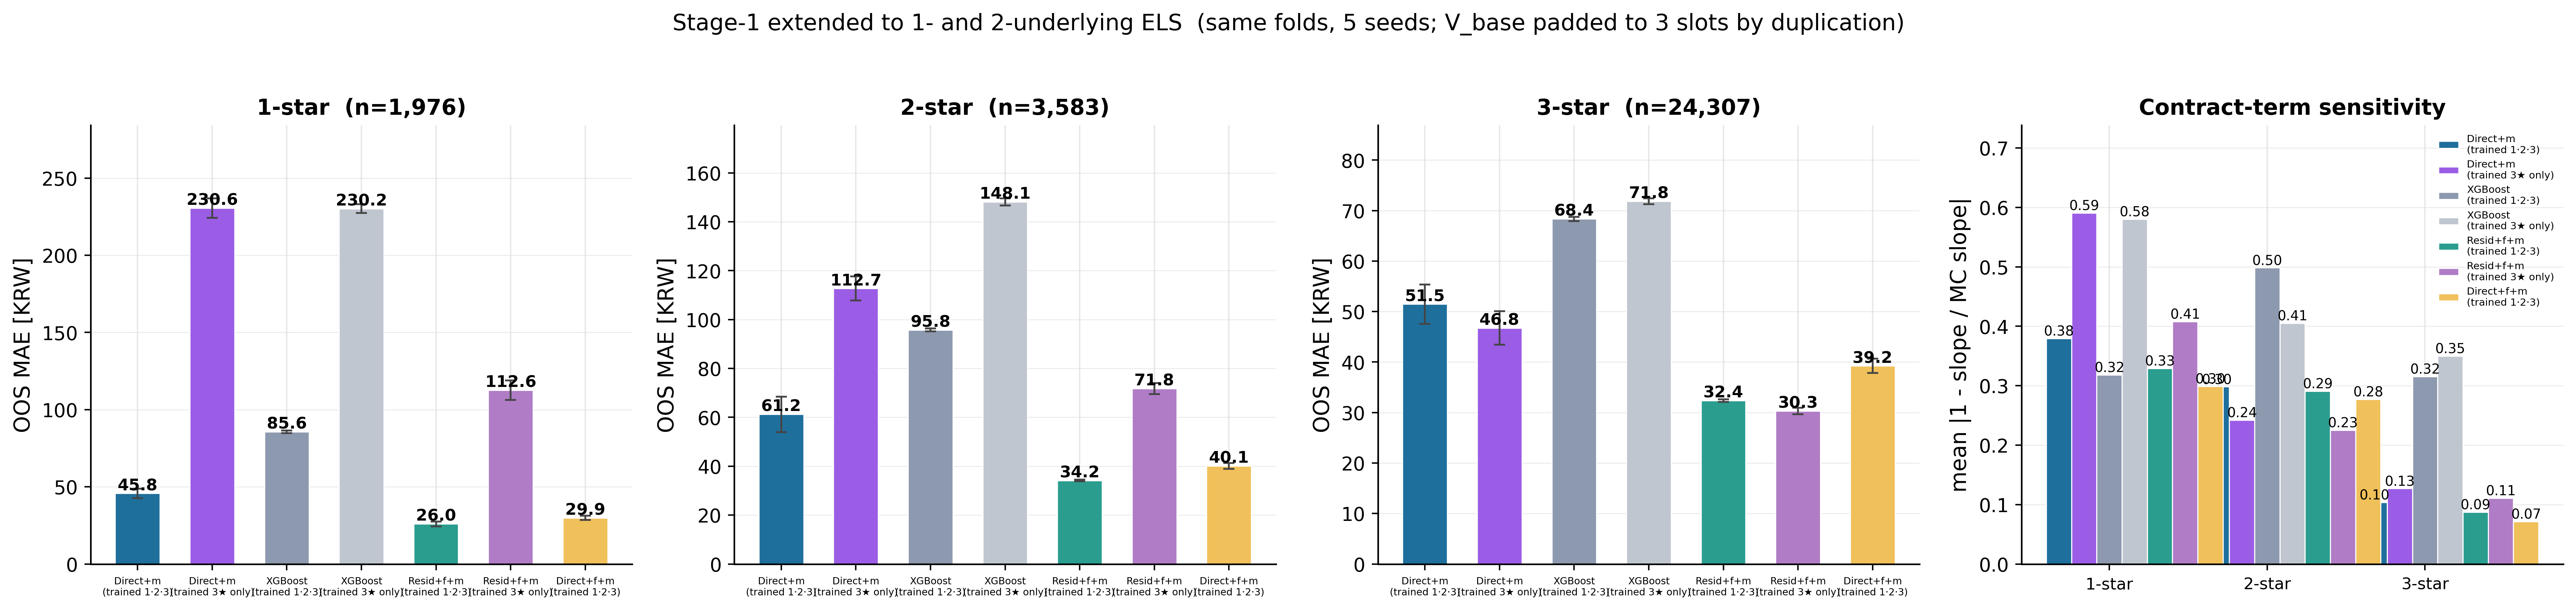

C:\Users\Juhwankim\Documents\Github\PI-DeepONet-ELS\tools\eval_cross_section.py:86: RuntimeWarning: All-NaN slice encountered
  lzb = np.nanmin(np.where(on, D.CON[:, CS.iLB], np.nan), 1)
C:\Users\Juhwankim\Documents\Github\PI-DeepONet-ELS\tools\eval_cross_section.py:87: RuntimeWarning: All-NaN slice encountered
  lzp = np.nanmax(np.where(on, D.CON[:, CS.iLP], np.nan), 1)


예측 완료 (1s)



=== 1스타 | 잔차회귀 (모델 − MC) ~ 계약조건.  0 이면 MC 와 동일 반응 ===
  KI barrier (n=1,976, MC 기울기 +15.2)
     Direct+m (1·2·3)             +88.0 ±   10.8  (MC 대비 +581.0%)  t   +8.1  <- 유의
     Direct+m (3star only)       +189.4 ±   26.5  (MC 대비 +1249.9%)  t   +7.2  <- 유의
     XGBoost (1·2·3)             +173.2 ±   22.0  (MC 대비 +1142.9%)  t   +7.9  <- 유의
  coupon (annual) (n=1,976, MC 기울기 -7473.5)
     Direct+m (1·2·3)           -1409.5 ±   89.9  (MC 대비  +18.9%)  t  -15.7  <- 유의
     Direct+m (3star only)      -4349.2 ±  321.8  (MC 대비  +58.2%)  t  -13.5  <- 유의
     XGBoost (1·2·3)            -2859.2 ±  130.9  (MC 대비  +38.3%)  t  -21.8  <- 유의
  first strike (n=1,976, MC 기울기 -796.9)
     Direct+m (1·2·3)             -20.2 ±   33.7  (MC 대비   +2.5%)  t   -0.6
     Direct+m (3star only)       -983.0 ±  114.8  (MC 대비 +123.4%)  t   -8.6  <- 유의
     XGBoost (1·2·3)             -119.3 ±   65.2  (MC 대비  +15.0%)  t   -1.8
  step-down width (n=1,976, MC 기울기 +2659.9)
     Direct+m (1·2·3)             +53.5 ±   2

In [14]:
from IPython.display import Image, display
from tools import eval_all_stars, eval_cross_section

if Path(fm.stat("mc_check_allstar")).exists():
    eval_all_stars.main()
    display(Image(filename=str(fm.image("allstar"))))
else:
    print("건너뜀: mc_check_allstar.csv 가 없다 — 노트북 1 의 1-0 을 먼저 돌린다")

eval_cross_section.main()

## 저장된 그림

In [15]:
for i, n in enumerate(saved, 1):
    print("{:2d}. {}".format(i, n))
print()
print("총 {}장 | 위치 {}".format(len(saved), fm.image("x").parent))

 1. cat1_1star_level.png
 2. cat1_2star_level.png
 3. cat1_3star_level.png
 4. cat1_1star_terms_ols.png
 5. cat1_2star_terms_ols.png
 6. cat1_3star_terms_ols.png
 7. cat1_1star_terms_binned.png
 8. cat1_2star_terms_binned.png
 9. cat1_3star_terms_binned.png
10. cat2_1star_by_underlying.png
11. cat2_1star_by_structure.png
12. cat2_2star_by_underlying.png
13. cat2_2star_by_structure.png
14. cat2_3star_by_underlying.png
15. cat2_3star_by_structure.png
16. cat3_fair_minus_mc_hist.png
17. cat3_err_by_price_seg.png
18. cat3_by_year.png
19. cat3_decomposition.png
20. cat3_speed.png
21. cat4_universe_fair.png
22. cat4_universe_time.png

총 22장 | 위치 C:\Users\Juhwankim\Documents\Github\PI-DeepONet-ELS\result\image
